
# 7. Product Demand Forecasting

## 7.1 Data Preparation and Feasibility

### 7.1.1 Product and Store Lookup Tables

We will prepare product and store reference tables for our forecasting system.

These tables will help us:

- Identify products using readable labels.
- Preserve product categories and package information.
- Identify stores using unique store IDs.
- Support product and store selection in Streamlit.

The original IDs will be preserved for model predictions.


In [70]:
from pathlib import Path
import sys

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sqlalchemy import text, bindparam
from sklearn.metrics import mean_absolute_error, mean_squared_error

from sklearn.base import clone
from sklearn.compose import ColumnTransformer, TransformedTargetRegressor
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import Pipeline
from xgboost import XGBRegressor
import lightgbm as lgb
import optuna

import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers


PROJECT_ROOT = Path.cwd().resolve().parent

if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

from src.data.database import get_engine

engine = get_engine()

In [2]:
# Create output directory
forecast_dir = PROJECT_ROOT / "data" / "processed" / "forecasting"
forecast_dir.mkdir(parents=True, exist_ok=True)

In [3]:
# Load product information
query = text("""
    SELECT
        PRODUCT_ID,
        DEPARTMENT,
        COMMODITY_DESC,
        SUB_COMMODITY_DESC,
        BRAND,
        CURR_SIZE_OF_PRODUCT
    FROM raw_product
""")

with engine.connect() as connection:
    product_lookup = pd.read_sql_query(query, connection)

# Check product identifiers
assert product_lookup["PRODUCT_ID"].notna().all()
assert product_lookup["PRODUCT_ID"].is_unique

In [5]:
# Prepare readable product descriptions
product_description = (
    product_lookup["SUB_COMMODITY_DESC"]
    .fillna("")
    .astype(str)
    .str.strip()
)

# Use commodity description when subcategory is unavailable
missing_description = (
    product_description.eq("")
    | product_description.str.upper().str.startswith(
        "NO SUBCOMMODITY DESCRIPTION"
    )
)

product_description = product_description.mask(
    missing_description,
    product_lookup["COMMODITY_DESC"]
    .fillna("Unknown Product")
    .astype(str)
    .str.strip()
)

product_size = (
    product_lookup["CURR_SIZE_OF_PRODUCT"]
    .fillna("")
    .astype(str)
    .str.strip()
)

# Create product labels
product_lookup["product_label"] =(
    product_description
    + np.where(product_size.ne(""), " | " + product_size, "" )
    + " | ID: "
    + product_lookup["PRODUCT_ID"].astype(str)
)

# Save product lookup
product_lookup.to_csv(
    forecast_dir / "product_lookup.csv",
    index=False
)

print("Total Products:", len(product_lookup))

display(product_lookup.head(10))

Total Products: 92353


,PRODUCT_ID,DEPARTMENT,COMMODITY_DESC,SUB_COMMODITY_DESC,BRAND,CURR_SIZE_OF_PRODUCT,product_label
0,25671,GROCERY,FRZN ICE,ICE - CRUSHED/CUBED,National,22 LB,ICE - CRUSHED/CUBED | 22 LB | ID: 25671
1,26081,MISC. TRANS.,NO COMMODITY DESCRIPTION,NO SUBCOMMODITY DESCRIPTION,National,,NO COMMODITY DESCRIPTION | ID: 26081
2,26093,PASTRY,BREAD,BREAD:ITALIAN/FRENCH,Private,,BREAD:ITALIAN/FRENCH | ID: 26093
3,26190,GROCERY,FRUIT - SHELF STABLE,APPLE SAUCE,Private,50 OZ,APPLE SAUCE | 50 OZ | ID: 26190
4,26355,GROCERY,COOKIES/CONES,SPECIALTY COOKIES,Private,14 OZ,SPECIALTY COOKIES | 14 OZ | ID: 26355
5,26426,GROCERY,SPICES & EXTRACTS,SPICES & SEASONINGS,Private,2.5 OZ,SPICES & SEASONINGS | 2.5 OZ | ID: 26426
6,26540,GROCERY,COOKIES/CONES,TRAY PACK/CHOC CHIP COOKIES,Private,16 OZ,TRAY PACK/CHOC CHIP COOKIES | 16 OZ | ID: 26540
7,26601,DRUG GM,VITAMINS,VITAMIN - MINERALS,Private,300CT(1),VITAMIN - MINERALS | 300CT(1) | ID: 26601
8,26636,PASTRY,BREAKFAST SWEETS,SW GDS: SW ROLLS/DAN,Private,,SW GDS: SW ROLLS/DAN | ID: 26636
9,26691,GROCERY,PNT BTR/JELLY/JAMS,HONEY,Private,12 OZ,HONEY | 12 OZ | ID: 26691


In [6]:
# Load store information from transactions
query = text("""
    SELECT
        STORE_ID,
        COUNT(*) AS transaction_count,
        COUNT(DISTINCT BASKET_ID) AS basket_count,
        COUNT(DISTINCT household_key) AS customer_count,
        MIN(`DAY`) AS first_day,
        MAX(`DAY`) AS last_day

    FROM raw_transaction_data

    WHERE STORE_ID IS NOT NULL

    GROUP BY STORE_ID
    ORDER BY STORE_ID
""")

with engine.connect() as connection:
    store_lookup = pd.read_sql_query(query, connection)

# Preserve a field for future real store names
store_lookup["store_name"] = pd.NA

# Create readable fallback labels
store_lookup["store_label"] = (
    "Store " + store_lookup["STORE_ID"].astype(str)
)

# Validate identifiers
assert store_lookup["STORE_ID"].is_unique
assert store_lookup["STORE_ID"].notna().all()

# Save store lookup
store_lookup.to_csv(
    forecast_dir / "store_lookup.csv",
    index=False
)

print("Total Stores:", len(store_lookup))

display(store_lookup.head(10))

Total Stores: 582


,STORE_ID,transaction_count,basket_count,customer_count,first_day,last_day,store_name,store_label
0,1,4,3,2,29,96,<NA>,Store 1
1,2,5,3,1,281,698,<NA>,Store 2
2,12,4,1,1,382,382,<NA>,Store 12
3,19,8,3,1,611,684,<NA>,Store 19
4,20,2,2,1,354,354,<NA>,Store 20
5,21,4,2,1,50,51,<NA>,Store 21
6,22,4,1,1,218,218,<NA>,Store 22
7,26,2,1,1,434,434,<NA>,Store 26
8,27,836,67,22,3,642,<NA>,Store 27
9,37,3,1,1,468,468,<NA>,Store 37



### 7.1.2 Product Demand Feasibility Analysis

Before forecasting product demand, we will examine product sales quantities.

Our objectives are:

- Identify unusual transaction quantities.
- Examine quantity distributions by product category.
- Identify categories that may not represent regular retail products.
- Prepare a reliable product universe for demand forecasting.

We will use only the training period to select eligible products.


In [7]:
# Use historical training data only
TRAIN_END_DAY = 621

query = text("""
    SELECT
        COALESCE(p.DEPARTMENT, 'UNKNOWN') AS department,
        COALESCE(p.COMMODITY_DESC, 'UNKNOWN') AS commodity,

        COUNT(*) AS transaction_rows,

        COUNT(DISTINCT t.PRODUCT_ID) AS unique_products,

        SUM(
            CASE WHEN t.QUANTITY <= 0 THEN 1 ELSE 0 END
        ) AS nonpositive_qty_rows,

        SUM(
            CASE WHEN t.QUANTITY > 100 THEN 1 ELSE 0 END
        ) AS qty_over_100_rows,

        ROUND(
            AVG(
                CASE
                    WHEN t.QUANTITY > 0 THEN t.QUANTITY
                    ELSE NULL
                END
            ), 2
        ) AS avg_positive_qty,

        MAX(t.QUANTITY) AS max_quantity,

        SUM(
            CASE
                WHEN t.QUANTITY > 0 THEN t.QUANTITY
                ELSE 0
            END
        ) AS total_positive_quantity

    FROM raw_transaction_data AS t

    LEFT JOIN raw_product AS p
        ON t.PRODUCT_ID = p.PRODUCT_ID
    
    WHERE t.`DAY` BETWEEN 1 AND :train_end_day

    GROUP BY
        p.DEPARTMENT,
        p.COMMODITY_DESC

    ORDER BY total_positive_quantity DESC
""")

with engine.connect() as connection:
    quantity_analysis = pd.read_sql_query(
        query,
        connection,
        params={"train_end_day": TRAIN_END_DAY}
    )

print("Product Categories:", len(quantity_analysis))

display(quantity_analysis.head(20))

Product Categories: 357


,department,commodity,transaction_rows,unique_products,nonpositive_qty_rows,qty_over_100_rows,avg_positive_qty,max_quantity,total_positive_quantity
0,KIOSK-GAS,COUPON/MISC ITEMS,17511,10,0.0,17504.0,10817.77,89638,189429894.0
1,MISC SALES TRAN,COUPON/MISC ITEMS,5190,72,48.0,2470.0,6001.69,85055,30860693.0
2,GROCERY,SOFT DRINKS,101787,1647,272.0,0.0,1.37,50,139117.0
3,KIOSK-GAS,FUEL,1475,6,0.0,6.0,80.88,30080,119304.0
4,GROCERY,FLUID MILK PRODUCTS,73071,432,108.0,0.0,1.35,28,98789.0
5,GROCERY,BAKED BREAD/BUNS/ROLLS,71864,1098,86.0,0.0,1.20,26,86047.0
6,GROCERY,CHEESE,63560,1042,54.0,0.0,1.29,36,81870.0
7,GROCERY,SOUP,37639,791,34.0,0.0,1.88,54,70844.0
8,GROCERY,BAG SNACKS,57421,1445,94.0,0.0,1.21,43,69228.0
9,GROCERY,FRZN MEAT/MEAT DINNERS,47895,1203,63.0,0.0,1.42,21,67858.0



### 7.1.3 Product-Level Demand Profiling

We will analyze sales activity for each product.

Our objectives are:

- Calculate total units sold.
- Measure the number of active sales days.
- Identify products with regular sales activity.
- Examine the time between the first and last observed sale.
- Identify unusual transaction quantities.

We will use only the training period to select eligible products.

Special transaction departments will be excluded.


In [8]:
# Define training period
TRAIN_END_DAY = 531

# Exclude special transaction departments
EXCLUDED_DEPARTMENTS = [
    "KIOSK-GAS",
    "MISC SALES TRAN",
]

query = text("""
    SELECT
        t.PRODUCT_ID,

        COUNT(*) AS transaction_rows,

        SUM(
            CASE WHEN t.QUANTITY > 0
            THEN t.QUANTITY ELSE 0 END
        ) AS total_quantity,

        COUNT(DISTINCT
            CASE WHEN t.QUANTITY > 0
            THEN t.`DAY` ELSE NULL END
        ) AS active_sales_days,

        MIN(
            CASE WHEN t.QUANTITY > 0
            THEN t.`DAY` ELSE NULL END
        ) AS first_sale_day,

        MAX(
            CASE WHEN t.QUANTITY > 0
            THEN t.`DAY` ELSE NULL END
        ) AS last_sale_day,

        COUNT(DISTINCT
            CASE WHEN t.QUANTITY > 0
            THEN t.STORE_ID ELSE NULL END
        ) AS active_store_count,

        MAX(
            CASE WHEN t.QUANTITY > 0
            THEN t.QUANTITY ELSE NULL END
        ) AS max_transaction_qty,

        SUM(
            CASE WHEN t.QUANTITY > 100
            THEN 1 ELSE 0 END
        ) AS qty_over_100_rows,

        SUM(
            CASE WHEN t.QUANTITY <= 0
            THEN 1 ELSE 0 END
        ) AS nonpositive_qty_rows

    FROM raw_transaction_data AS t

    INNER JOIN raw_product AS p
        ON t.PRODUCT_ID = p.PRODUCT_ID
    
    WHERE t.`DAY` BETWEEN 1 AND :train_end_day
      AND p.DEPARTMENT NOT IN (
          'KIOSK-GAS',
          'MISC SALES TRAN'
      )

    GROUP BY t.PRODUCT_ID

    HAVING total_quantity > 0
""")

with engine.connect() as connection:
    product_demand_profile = pd.read_sql_query(
        query,
        connection,
        params={"train_end_day": TRAIN_END_DAY},
    )

# Calculate observed sales period
product_demand_profile["observed_span_days"] = (
    product_demand_profile["last_sale_day"]
    - product_demand_profile["first_sale_day"]
    + 1
)

# Calculate days without observed sales
product_demand_profile["no_sale_day_ratio"] = (
    1
    - (
        product_demand_profile["active_sales_days"]
        / product_demand_profile["observed_span_days"]
    )
)

# Calculate average sales on active days
product_demand_profile["avg_qty_per_active_day"] = (
    product_demand_profile["total_quantity"]
    / product_demand_profile["active_sales_days"]
)

# Calculate time since last observed sale
product_demand_profile["days_since_last_sale"] = (
    TRAIN_END_DAY
    - product_demand_profile["last_sale_day"]
)

# Add readable product labels
product_demand_profile = product_demand_profile.merge(
    product_lookup[
        ["PRODUCT_ID", "product_label", "DEPARTMENT"]
    ],
    on="PRODUCT_ID",
    how="left",
    validate="one_to_one",
)

# Validate results
assert product_demand_profile["PRODUCT_ID"].is_unique
assert product_demand_profile["product_label"].notna().all()
assert product_demand_profile["no_sale_day_ratio"].between(0, 1).all()

print("Analyzed Products:", len(product_demand_profile))

display(
    product_demand_profile.sort_values(
        "total_quantity",
        ascending=False,
    ).head(15).round(3)
)

Analyzed Products: 78481


,PRODUCT_ID,transaction_rows,total_quantity,active_sales_days,first_sale_day,last_sale_day,active_store_count,max_transaction_qty,qty_over_100_rows,nonpositive_qty_rows,observed_span_days,no_sale_day_ratio,avg_qty_per_active_day,days_since_last_sale,product_label,DEPARTMENT
33095,1082185,21298,22083.0,529,1,531,111,9,0.0,18.0,531,0.004,41.745,0,BANANAS | 40 LB | ID: 1082185,PRODUCE
23776,995242,8975,15810.0,524,3,531,111,14,0.0,12.0,529,0.009,30.172,0,FLUID MILK WHITE ONLY | ID: 995242,GROCERY
27476,1029743,10358,12196.0,529,2,531,111,6,0.0,18.0,530,0.002,23.055,0,FLUID MILK WHITE ONLY | 1 GA | ID: 1029743,GROCERY
25064,1007195,1689,9670.0,351,8,531,108,32,0.0,10.0,524,0.330,27.550,0,CORN YELLOW | 48 CT | ID: 1007195,PRODUCE
38366,1133018,5320,9036.0,515,7,531,111,28,0.0,7.0,525,0.019,17.546,0,FLUID MILK WHITE ONLY | ID: 1133018,GROCERY
22355,981760,6852,8476.0,526,1,531,111,10,0.0,6.0,531,0.009,16.114,0,EGGS - X-LARGE | 1 DZ | ID: 981760,GROCERY
35635,1106523,7085,8253.0,526,1,531,111,6,0.0,29.0,531,0.009,15.690,0,FLUID MILK WHITE ONLY | 1 GA | ID: 1106523,GROCERY
37815,1127831,4647,6777.0,479,3,531,111,8,0.0,5.0,529,0.095,14.148,0,STRAWBERRIES | 16 OZ | ID: 1127831,PRODUCE
11887,883404,4868,6237.0,522,2,531,110,8,0.0,3.0,530,0.015,11.948,0,MAINSTREAM WHITE BREAD | 20 OZ | ID: 883404,GROCERY
10090,866227,2197,5925.0,503,3,531,108,20,0.0,20.0,529,0.049,11.779,0,SW GDS:DONUTS | ID: 866227,PASTRY



### 7.1.4 Product Demand Distribution Analysis

We will analyze product sales frequency and continuity.

Our goals are to:

- Understand the distribution of active sales days.
- Measure the frequency of days without recorded sales.
- Identify products with recent sales activity.
- Compare different product eligibility thresholds.

We will select products using training-period data only.


In [9]:
# Select demand activity metrics
demand_metrics = [
    "total_quantity",
    "active_sales_days",
    "observed_span_days",
    "no_sale_day_ratio",
    "days_since_last_sale",
    "active_store_count",
    "max_transaction_qty",
]

# Calculate distribution statistics
demand_distribution = (
    product_demand_profile[demand_metrics]
    .describe(
        percentiles=[0.25, 0.50, 0.75, 0.90, 0.95, 0.99]
    )
    .T
)

print("PRODUCT DEMAND DISTRIBUTION")

display(demand_distribution.round(3))

PRODUCT DEMAND DISTRIBUTION


,count,mean,std,min,25%,50%,75%,90%,95%,99%,max
total_quantity,78481.0,30.704,188.284,1.0,1.0,3.000,14.000,61.000,121.000,413.000,22083.000
active_sales_days,78481.0,16.810,40.821,1.0,1.0,3.000,12.000,46.000,83.000,205.000,529.000
observed_span_days,78481.0,183.879,194.083,1.0,1.0,102.000,381.000,483.000,507.000,525.000,531.000
no_sale_day_ratio,78481.0,0.577,0.450,0.0,0.0,0.878,0.968,0.985,0.989,0.993,0.996
days_since_last_sale,78481.0,154.085,147.295,0.0,20.0,108.000,261.000,391.000,436.000,497.000,530.000
active_store_count,78481.0,9.434,16.431,1.0,1.0,2.000,9.000,29.000,46.000,82.000,111.000
max_transaction_qty,78481.0,1.863,2.207,1.0,1.0,1.000,2.000,3.000,5.000,10.000,144.000


In [10]:
# Define candidate minimum active sales days
active_day_thresholds = [30, 60, 90, 120, 180, 240, 300]

eligibility_results = []

for min_days in active_day_thresholds:

    # Apply product eligibility conditions
    mask = (
        (product_demand_profile["active_sales_days"] >= min_days)
        & (product_demand_profile["observed_span_days"] >= 365)
        & (product_demand_profile["days_since_last_sale"] <= 30)
        & (product_demand_profile["no_sale_day_ratio"] <= 0.50)
    )

    eligible = product_demand_profile.loc[mask]

    eligibility_results.append({
        "min_active_days": min_days,
        "eligible_products": len(eligible),
        "product_share_pct": (
            len(eligible) / len(product_demand_profile) * 100
        ),
        "median_total_quantity": (
            eligible["total_quantity"].median()
        ),
        "median_no_sale_ratio": (
            eligible["no_sale_day_ratio"].median()
        ),
    })

eligibility_summary = pd.DataFrame(eligibility_results)

print("PRODUCT ELIGIBILITY COMPARISON")

display(eligibility_summary.round(3))

PRODUCT ELIGIBILITY COMPARISON


,min_active_days,eligible_products,product_share_pct,median_total_quantity,median_no_sale_ratio
0,30,457,0.582,861.0,0.356
1,60,457,0.582,861.0,0.356
2,90,457,0.582,861.0,0.356
3,120,457,0.582,861.0,0.356
4,180,457,0.582,861.0,0.356
5,240,457,0.582,861.0,0.356
6,300,305,0.389,1102.0,0.268



### 7.1.6 Final Product Selection

We will select products with regular historical sales activity.

Our selection criteria are:

- At least 240 active sales days.
- At least 365 days of observed sales history.
- No more than 50% of days without recorded sales.
- At least one sale in the last 30 training days.

We will use only training-period information to select products.

The selected product IDs and readable labels will be saved for forecasting and Streamlit.


In [11]:
# 1. Define product selection criteria
MIN_ACTIVE_DAYS = 240
MIN_HISTORY_DAYS = 365
MAX_NO_SALE_RATIO = 0.50
MAX_DAYS_SINCE_SALE = 30

# 2. Apply selection filters
eligible_mask = (
    (product_demand_profile["active_sales_days"] >= MIN_ACTIVE_DAYS)
    & (product_demand_profile["observed_span_days"] >= MIN_HISTORY_DAYS)
    & (product_demand_profile["no_sale_day_ratio"] <= MAX_NO_SALE_RATIO)
    & (product_demand_profile["days_since_last_sale"] <= MAX_DAYS_SINCE_SALE)
)

eligible_products = (
    product_demand_profile.loc[eligible_mask]
    .sort_values("total_quantity", ascending=False)
    .reset_index(drop=True)
    .copy()
)

# 3. Validate selected products
assert eligible_products["PRODUCT_ID"].is_unique
assert eligible_products["product_label"].notna().all()

print("Selected Products:", len(eligible_products))

print(
    "Selected Departments:",
    eligible_products["DEPARTMENT"].nunique()
)

# 4. Check unusual quantities in selected products
print(
    "Products With Quantity > 100:",
    int((eligible_products["qty_over_100_rows"] > 0).sum())
)

print(
    "Maximum Transaction Quantity:",
    eligible_products["max_transaction_qty"].max()
)

# 5. Display category distribution
department_summary = (
    eligible_products
    .groupby("DEPARTMENT")
    .agg(
        product_count=("PRODUCT_ID", "nunique"),
        total_quantity=("total_quantity", "sum"),
        median_active_days=("active_sales_days", "median"),
    )
    .sort_values("product_count", ascending=False)
)

display(department_summary)

# 6. Save selected products
eligible_products.to_csv(
    forecast_dir / "eligible_products.csv",
    index=False,
)

# 7. Save product labels for Streamlit
eligible_product_lookup = product_lookup.loc[
    product_lookup["PRODUCT_ID"].isin(
        eligible_products["PRODUCT_ID"]
    )
].copy()

eligible_product_lookup.to_csv(
    forecast_dir / "eligible_product_lookup.csv",
    index=False,
)

print("\nEligible product data saved successfully.")


Selected Products: 457
Selected Departments: 8
Products With Quantity > 100: 0
Maximum Transaction Quantity: 60


,product_count,total_quantity,median_active_days
DEPARTMENT,,,
GROCERY,291,413530.0,329.0
PRODUCE,77,154173.0,400.0
MEAT,26,32427.0,291.0
DRUG GM,22,23525.0,328.0
DELI,18,17049.0,342.5
MEAT-PCKGD,14,13849.0,315.0
PASTRY,6,11405.0,322.5
SALAD BAR,3,5429.0,424.0



Eligible product data saved successfully.


In [12]:
eligible_product_lookup.head()

,PRODUCT_ID,DEPARTMENT,COMMODITY_DESC,SUB_COMMODITY_DESC,BRAND,CURR_SIZE_OF_PRODUCT,product_label
5890,819765,GROCERY,CHEESE,NATURAL CHEESE EXACT WT CHUNKS,Private,8 OZ,NATURAL CHEESE EXACT WT CHUNKS | 8 OZ | ID: 81...
5907,819927,GROCERY,PASTA SAUCE,MAINSTREAM,National,26 OZ,MAINSTREAM | 26 OZ | ID: 819927
5915,819978,DELI,CHEESES,CHEESE: PROCESSED BULK,National,,CHEESE: PROCESSED BULK | ID: 819978
5937,820165,PRODUCE,CITRUS,ORANGES NAVELS ALL,National,,ORANGES NAVELS ALL | ID: 820165
6035,821083,GROCERY,EGGS,EGGS - JUMBO,Private,1 DOZ,EGGS - JUMBO | 1 DOZ | ID: 821083



## 7.2 Daily Product Sales Time Series

We will create daily sales time series for the 457 selected products.

Our objectives are:

- Aggregate transaction quantities by product and day.
- Create a complete daily time index.
- Identify days without recorded sales.
- Preserve product IDs for future forecasting.
- Prepare time series data for feature engineering.

We will use the full 711-day history to build the time series.

Product selection was completed using training data only.


In [14]:
# Forecasting parameters
MAX_DAY = 711

# Selected product IDs
selected_product_ids = (
    eligible_products["PRODUCT_ID"]
    .astype(int)
    .tolist()
)

query = text("""
    SELECT
        t.PRODUCT_ID,
        t.`DAY` AS DAY,

        SUM(t.QUANTITY) AS daily_quantity,

        COUNT(*) AS transaction_rows,

        COUNT(DISTINCT t.BASKET_ID) AS daily_baskets

    FROM raw_transaction_data AS t

    WHERE t.PRODUCT_ID IN :product_ids
      AND t.`DAY` BETWEEN 1 AND :max_day
      AND t.QUANTITY > 0
    
    GROUP BY
        t.PRODUCT_ID,
        t.`DAY`

    ORDER BY
        t.PRODUCT_ID,
        t.`DAY`
""").bindparams(
    bindparam("product_ids", expanding=True)
)

# Load daily product sales
with engine.connect() as connection:
    daily_sales = pd.read_sql_query(
        query,
        connection,
        params={
            "product_ids": selected_product_ids,
            "max_day": MAX_DAY,
        },
    )

# Validate aggregation
assert not daily_sales.duplicated(
    ["PRODUCT_ID", "DAY"]
).any()

assert (daily_sales["daily_quantity"] > 0).all()

print("Daily Sales Shape:", daily_sales.shape)
print("Unique Products:", daily_sales["PRODUCT_ID"].nunique())
print("Minimum Day:", daily_sales["DAY"].min())
print("Maximum Day:", daily_sales["DAY"].max())

display(daily_sales.head(10))

Daily Sales Shape: (218256, 5)
Unique Products: 457
Minimum Day: 1
Maximum Day: 711


,PRODUCT_ID,DAY,daily_quantity,transaction_rows,daily_baskets
0,819765,11,3.0,1,1
1,819765,21,2.0,1,1
2,819765,24,2.0,1,1
3,819765,26,2.0,1,1
4,819765,36,1.0,1,1
5,819765,38,2.0,1,1
6,819765,39,2.0,1,1
7,819765,49,1.0,1,1
8,819765,50,2.0,1,1
9,819765,57,2.0,2,2


In [15]:
# 1. Create complete product-day combinations
full_index = pd.MultiIndex.from_product(
    [
        selected_product_ids,
        range(1, MAX_DAY + 1),
    ],
    names = ["PRODUCT_ID", "DAY"]
)

# 2. Complete missing days with zero recorded sales
daily_product_series = (
    daily_sales.set_index(["PRODUCT_ID", "DAY"])
    .reindex(full_index, fill_value=0)
    .reset_index()
    .sort_values(["PRODUCT_ID", "DAY"])
    .reset_index(drop=True)
)

# 3. Preserve information about each product's first sale
first_sales = eligible_products[
    ["PRODUCT_ID", "first_sale_day"]
]

daily_product_series = daily_product_series.merge(
    first_sales,
    on="PRODUCT_ID",
    how="left",
    validate="many_to_one",
)

daily_product_series["before_first_sale"] = (
    daily_product_series["DAY"]
    < daily_product_series["first_sale_day"]
)

# 4. Validate time series
expected_rows = len(selected_product_ids) * MAX_DAY

assert len(daily_product_series) == expected_rows
assert daily_product_series["daily_quantity"].ge(0).all()
assert daily_product_series["PRODUCT_ID"].nunique() == 457
assert not daily_product_series.duplicated(
    ["PRODUCT_ID", "DAY"]
).any()

print("Daily Panel Shape:", daily_product_series.shape)
print("Expected Rows:", expected_rows)

print(
    "Zero Recorded Sales Ratio (%):",
    round(
        daily_product_series["daily_quantity"]
        .eq(0)
        .mean() * 100,
        2,
    )
)

print(
    "Rows Before First Sale:",
    daily_product_series["before_first_sale"].sum()
)

display(daily_product_series.head(10))

Daily Panel Shape: (324927, 7)
Expected Rows: 324927
Zero Recorded Sales Ratio (%): 32.83
Rows Before First Sale: 4346


,PRODUCT_ID,DAY,daily_quantity,transaction_rows,daily_baskets,first_sale_day,before_first_sale
0,819765,1,0.0,0,0,11,True
1,819765,2,0.0,0,0,11,True
2,819765,3,0.0,0,0,11,True
3,819765,4,0.0,0,0,11,True
4,819765,5,0.0,0,0,11,True
5,819765,6,0.0,0,0,11,True
6,819765,7,0.0,0,0,11,True
7,819765,8,0.0,0,0,11,True
8,819765,9,0.0,0,0,11,True
9,819765,10,0.0,0,0,11,True


,DAY,total_quantity,active_products
277,278,0.0,0
642,643,0.0,0


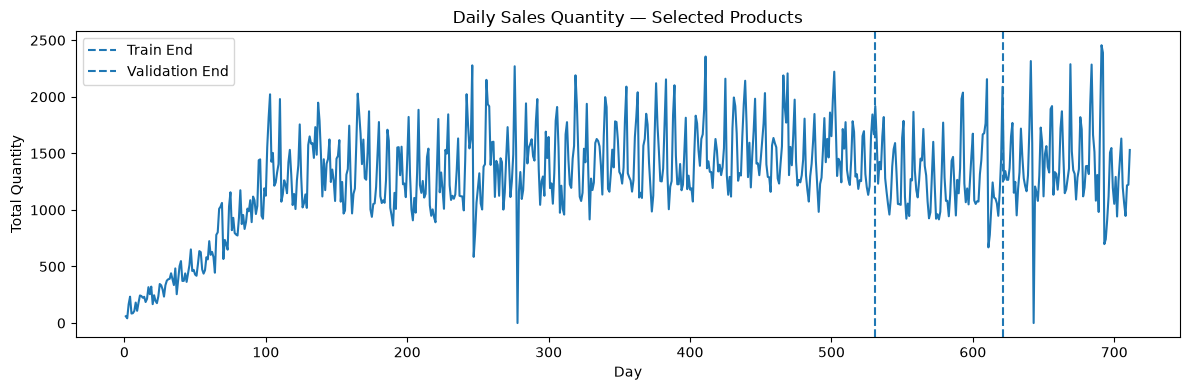

In [17]:
# Aggregate selected product sales by day
daily_total_sales = (
    daily_product_series
    .groupby("DAY", as_index=False)
    .agg(
        total_quantity=("daily_quantity", "sum"),
        active_products=(
            "daily_quantity",
            lambda x: x.gt(0).sum()
        )
    )
)

# Check previously identified unusual days
display(
    daily_total_sales.loc[
        daily_total_sales["DAY"].isin([278, 643])
    ]
)

# Plot daily sales quantity
plt.figure(figsize=(12, 4))

plt.plot(
    daily_total_sales["DAY"],
    daily_total_sales["total_quantity"],
)

plt.axvline(
    531,
    linestyle="--",
    label="Train End",
)

plt.axvline(
    621,
    linestyle="--",
    label="Validation End",
)

plt.title("Daily Sales Quantity — Selected Products")
plt.xlabel("Day")
plt.ylabel("Total Quantity")
plt.legend()
plt.tight_layout()
plt.show()

In [18]:

# Create readable category labels for Streamlit
eligible_product_lookup["category_label"] = (
    eligible_product_lookup["DEPARTMENT"].fillna("UNKNOWN").str.strip()
    + " / "
    + eligible_product_lookup["COMMODITY_DESC"].fillna("UNKNOWN").str.strip()
)

# Save updated product lookup
eligible_product_lookup.to_csv(
    forecast_dir / "eligible_product_lookup.csv",
    index=False,
)

print(
    "Eligible Products:",
    eligible_product_lookup["PRODUCT_ID"].nunique()
)

print(
    "Available Categories:",
    eligible_product_lookup["category_label"].nunique()
)

display(
    eligible_product_lookup[
        ["PRODUCT_ID", "category_label", "product_label"]
    ].head(10)
)


Eligible Products: 457
Available Categories: 97


,PRODUCT_ID,category_label,product_label
5890,819765,GROCERY / CHEESE,NATURAL CHEESE EXACT WT CHUNKS | 8 OZ | ID: 81...
5907,819927,GROCERY / PASTA SAUCE,MAINSTREAM | 26 OZ | ID: 819927
5915,819978,DELI / CHEESES,CHEESE: PROCESSED BULK | ID: 819978
5937,820165,PRODUCE / CITRUS,ORANGES NAVELS ALL | ID: 820165
6035,821083,GROCERY / EGGS,EGGS - JUMBO | 1 DOZ | ID: 821083
6202,822407,GROCERY / MEAT - SHELF STABLE,PASTA: CANNED | 15 OZ | ID: 822407
6251,822785,GROCERY / COCOA MIXES,MALTED MLK/SYRUP/PWDRS (EGGNOG | 24 OZ | ID: 8...
6354,823704,MEAT-PCKGD / BREAKFAST SAUSAGE/SANDWICHES,ROLLS - PORK | 16 OZ | ID: 823704
6363,823758,GROCERY / MARGARINES,MARGARINE STICK | L 16 OZ | ID: 823758
6391,824005,PRODUCE / MUSHROOMS,MUSHROOMS WHITE SLICED PKG | 8 OZ | ID: 824005



### 7.2.3 Global Daily Activity Validation

We identified two days with zero recorded sales for all selected products.

We will check whether these days also have zero transactions in the full dataset.

Our goals are:

- Identify days without transaction records.
- Compare global transaction activity with selected product sales.
- Detect possible missing or inactive days.
- Prevent unusual days from affecting forecasting features and targets.


In [19]:
# 1. Check daily transactions across the full dataset
query = text("""
    SELECT
        `DAY` AS DAY,
        COUNT(*) AS all_transaction_rows,
        COUNT(DISTINCT BASKET_ID) AS all_baskets

    FROM raw_transaction_data

    WHERE `DAY` BETWEEN 1 AND :max_day

    GROUP BY `DAY`
    ORDER BY `DAY`
""")

with engine.connect() as connection:
    global_daily_activity = pd.read_sql_query(
        query,
        connection,
        params={"max_day": MAX_DAY},
    )

# 2. Create the complete day index
all_days = pd.DataFrame({
    "DAY": np.arange(1, MAX_DAY + 1)
})

# 3. Include days without transaction records
daily_activity_check = all_days.merge(
    global_daily_activity,
    on="DAY",
    how="left",
    validate="one_to_one",
)

daily_activity_check[
    ["all_transaction_rows", "all_baskets"]
] = daily_activity_check[
    ["all_transaction_rows", "all_baskets"]
].fillna(0)

# 4. Add selected product sales activity
daily_activity_check = daily_activity_check.merge(
    daily_total_sales,
    on="DAY",
    how="left",
    validate="one_to_one",
)

# 5. Identify days without any transaction records
inactive_days = daily_activity_check.loc[
    daily_activity_check["all_transaction_rows"].eq(0),
    "DAY",
].tolist()


print("Days Without Any Transactions:", inactive_days)

print("\nUNUSUAL DAY ANALYSIS")

display(
    daily_activity_check.loc[
        daily_activity_check["DAY"].isin([278, 643])
    ]
)

# 6. Display the lowest transaction activity days
print("\nLOWEST TRANSACTION ACTIVITY")

display(
    daily_activity_check.nsmallest(
        10,
        "all_transaction_rows",
    )
)

Days Without Any Transactions: []

UNUSUAL DAY ANALYSIS


,DAY,all_transaction_rows,all_baskets,total_quantity,active_products
277,278,6,1,0.0,0
642,643,2,1,0.0,0



LOWEST TRANSACTION ACTIVITY


,DAY,all_transaction_rows,all_baskets,total_quantity,active_products
642,643,2,1,0.0,0
277,278,6,1,0.0,0
1,2,137,13,42.0,32
0,1,238,16,60.0,41
4,5,307,25,84.0,51
5,6,338,37,87.0,54
8,9,362,39,108.0,60
7,8,434,43,181.0,90
6,7,465,34,107.0,70
9,10,490,51,180.0,86



### 7.2.4 Unusual Daily Activity Investigation

We identified two days with extremely low transaction activity.

Days 278 and 643 are exactly 365 days apart.

This may indicate a recurring annual event or store closure.

We will examine the transactions and surrounding days before deciding how to handle these observations.

We will not automatically remove or replace these days.


In [20]:

# Examine transactions on unusual days
query = text("""
    SELECT
        t.`DAY` AS DAY,
        t.STORE_ID,
        t.BASKET_ID,
        t.PRODUCT_ID,
        p.DEPARTMENT,
        p.COMMODITY_DESC,
        t.QUANTITY,
        t.SALES_VALUE

    FROM raw_transaction_data AS t

    LEFT JOIN raw_product AS p
        ON t.PRODUCT_ID = p.PRODUCT_ID

    WHERE t.`DAY` IN (278, 643)

    ORDER BY
        t.`DAY`,
        t.STORE_ID,
        t.BASKET_ID
""")

with engine.connect() as connection:
    unusual_transactions = pd.read_sql_query(
        query,
        connection,
    )

print("UNUSUAL DAY TRANSACTIONS")

display(unusual_transactions)


UNUSUAL DAY TRANSACTIONS


,DAY,STORE_ID,BASKET_ID,PRODUCT_ID,DEPARTMENT,COMMODITY_DESC,QUANTITY,SALES_VALUE
0,278,2734,31126387287,3692358,DRUG GM,VITAMINS,1,5.59
1,278,2734,31126387287,3773679,PRODUCE,APPLES,1,3.17
2,278,2734,31126387287,3841423,DRUG GM,ANALGESICS,1,3.69
3,278,2734,31126387287,3894307,PRODUCE,CITRUS,1,2.19
4,278,2734,31126387287,3938042,GROCERY,REFRGRATD JUICES/DRNKS,1,1.98
5,278,2734,31126387287,6658823,DRUG GM,FIRST AID PRODUCTS,1,5.87
6,643,31782,41400285005,1104475,GROCERY,FROZEN PIZZA,1,2.00
7,643,31782,41400285005,17168855,GROCERY,NEW AGE,1,0.99


In [21]:
# Compare activity around unusual days
unusual_days = [278, 643]

nearby_activity = daily_activity_check.loc[
    daily_activity_check["DAY"].apply(
        lambda day: any(
            abs(day - unusual_day) <= 5
            for unusual_day in unusual_days
        )
    ),
    [
        "DAY",
        "all_transaction_rows",
        "all_baskets",
        "total_quantity",
        "active_products",
    ],
].copy()

display(nearby_activity)

,DAY,all_transaction_rows,all_baskets,total_quantity,active_products
272,273,3685,433,1114.0,290
273,274,3535,436,1254.0,319
274,275,4425,424,1491.0,327
275,276,6715,582,2270.0,388
276,277,4160,497,1540.0,325
277,278,6,1,0.0,0
278,279,3188,409,1164.0,311
279,280,3814,410,1335.0,336
280,281,2940,370,1097.0,312
281,282,3331,397,1175.0,302



## 7.3 Daily and Weekly Demand Analysis

### 7.3.1 Seven-Day Sales Pattern

We will examine weekly patterns in product sales.

Our objectives are:

- Identify repeated seven-day sales patterns.
- Compare average daily sales across week positions.
- Analyze the number of active products.
- Understand weekly seasonality before feature engineering.

We will use training data only.

The first 100 days and identified unusual days will be excluded from this exploratory comparison.


In [22]:
daily_total_sales.head()

,DAY,total_quantity,active_products
0,1,60.0,41
1,2,42.0,32
2,3,166.0,80
3,4,233.0,114
4,5,84.0,51


In [23]:
# 1. Define analysis period
ANALYSIS_START_DAY = 101
TRAIN_END_DAY = 531

UNUSUAL_DAYS = [278, 643]

# 2. Select training-period daily sales
weekly_analysis = daily_total_sales.loc[
    daily_total_sales["DAY"].between(
        ANALYSIS_START_DAY,
        TRAIN_END_DAY,
    )
    & ~daily_total_sales["DAY"].isin(UNUSUAL_DAYS)
].copy()

# 3. Create seven-day cycle position
weekly_analysis["week_position"] = (
    (weekly_analysis["DAY"] - 1) % 7
) + 1

# 4. Calculate weekly sales statistics
weekly_summary = (
    weekly_analysis
    .groupby("week_position")
    .agg(
        days=("DAY", "count"),
        avg_quantity=("total_quantity", "mean"),
        median_quantity=("total_quantity", "median"),
        avg_active_products=("active_products", "mean"),
    )
    .reset_index()
)

# 5. Compare with overall daily average
overall_avg = weekly_analysis["total_quantity"].mean()

weekly_summary["vs_overall_avg_pct"] = (
    (weekly_summary["avg_quantity"] / overall_avg - 1)
    * 100
)

print("WEEKLY DEMAND SUMMARY")

display(weekly_summary.round(2))

WEEKLY DEMAND SUMMARY


,week_position,days,avg_quantity,median_quantity,avg_active_products,vs_overall_avg_pct
0,1,61,1260.90,1254.0,314.70,-11.71
1,2,61,1228.15,1199.0,310.84,-14.00
2,3,62,1359.03,1370.0,324.90,-4.84
3,4,62,1661.89,1641.0,350.73,16.37
4,5,61,1799.82,1812.0,361.23,26.03
5,6,62,1420.94,1385.5,332.02,-0.50
6,7,61,1263.70,1247.0,315.93,-11.51


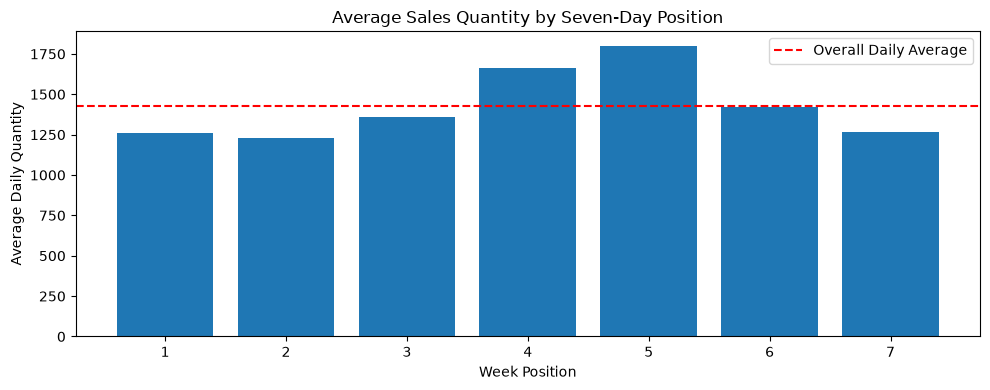

In [24]:

# Visualize seven-day sales pattern
fig, ax = plt.subplots(figsize=(10, 4))

ax.bar(
    weekly_summary["week_position"],
    weekly_summary["avg_quantity"],
)

ax.axhline(
    overall_avg,
    linestyle="--",
    color="red",
    label="Overall Daily Average",
)

ax.set_title("Average Sales Quantity by Seven-Day Position")
ax.set_xlabel("Week Position")
ax.set_ylabel("Average Daily Quantity")
ax.set_xticks(range(1, 8))

ax.legend()
plt.tight_layout()
plt.show()



### 7.3.3 Department-Level Weekly Demand Analysis

We will analyze weekly sales patterns across product departments.

Our goals are to:

- Compare weekly sales patterns by department.
- Identify departments with strong weekly seasonality.
- Understand differences in product demand.
- Support future feature engineering.

We will use training-period data only.


In [26]:
daily_product_series.head()

,PRODUCT_ID,DAY,daily_quantity,transaction_rows,daily_baskets,first_sale_day,before_first_sale
0,819765,1,0.0,0,0,11,True
1,819765,2,0.0,0,0,11,True
2,819765,3,0.0,0,0,11,True
3,819765,4,0.0,0,0,11,True
4,819765,5,0.0,0,0,11,True


In [27]:
eligible_product_lookup.head()

,PRODUCT_ID,DEPARTMENT,COMMODITY_DESC,SUB_COMMODITY_DESC,BRAND,CURR_SIZE_OF_PRODUCT,product_label,category_label
5890,819765,GROCERY,CHEESE,NATURAL CHEESE EXACT WT CHUNKS,Private,8 OZ,NATURAL CHEESE EXACT WT CHUNKS | 8 OZ | ID: 81...,GROCERY / CHEESE
5907,819927,GROCERY,PASTA SAUCE,MAINSTREAM,National,26 OZ,MAINSTREAM | 26 OZ | ID: 819927,GROCERY / PASTA SAUCE
5915,819978,DELI,CHEESES,CHEESE: PROCESSED BULK,National,,CHEESE: PROCESSED BULK | ID: 819978,DELI / CHEESES
5937,820165,PRODUCE,CITRUS,ORANGES NAVELS ALL,National,,ORANGES NAVELS ALL | ID: 820165,PRODUCE / CITRUS
6035,821083,GROCERY,EGGS,EGGS - JUMBO,Private,1 DOZ,EGGS - JUMBO | 1 DOZ | ID: 821083,GROCERY / EGGS


In [28]:
# 1. Add department information
department_daily = daily_product_series.merge(
    eligible_product_lookup[
        ["PRODUCT_ID", "DEPARTMENT"]
    ],
    on="PRODUCT_ID",
    how="left",
    validate="many_to_one",
)

# 2. Select stable training period
department_daily = department_daily.loc[
    department_daily["DAY"].between(101, 531)
    & ~department_daily["DAY"].isin([278])
].copy()

# 3. Create weekly cycle position
department_daily["week_position"] = (
    (department_daily["DAY"] - 1) % 7
) + 1

# 4. Aggregate daily quantity by department
department_daily = (
    department_daily
    .groupby(
        ["DEPARTMENT", "DAY", "week_position"],
        as_index=False
    )
    .agg(
        daily_quantity=("daily_quantity", "sum")
    )
)

# 5. Calculate average quantity by week position
department_weekly = (
    department_daily
    .groupby(["DEPARTMENT", "week_position"])
    .agg(
        avg_quantity=("daily_quantity", "mean")
    )
    .reset_index()
)

# 6. Calculate department-level daily averages
department_averages = (
    department_daily
    .groupby("DEPARTMENT")["daily_quantity"]
    .mean()
    .rename("department_avg")
)

# 7. Compare weekly sales with department averages
department_weekly = department_weekly.merge(
    department_averages,
    on="DEPARTMENT",
    validate="many_to_one",
)

department_weekly["deviation_pct"] = (
    (
        department_weekly["avg_quantity"]
        / department_weekly["department_avg"]
        - 1
    ) * 100
)

# 8. Create comparison matrix
department_weekly_matrix = (
    department_weekly
    .pivot(
        index="DEPARTMENT",
        columns="week_position",
        values="deviation_pct",
    )
)

print("DEPARTMENT WEEKLY DEMAND PATTERN")

display(department_weekly_matrix.round(2))


DEPARTMENT WEEKLY DEMAND PATTERN


week_position,1,2,3,4,5,6,7
DEPARTMENT,,,,,,,
DELI,-9.91,-9.14,-10.74,7.87,23.78,6.35,-8.27
DRUG GM,-6.88,1.57,-4.29,15.23,6.90,-4.16,-8.48
GROCERY,-12.91,-14.27,-3.11,18.94,26.32,-2.44,-12.75
MEAT,-9.17,-18.59,-15.97,13.00,35.56,5.09,-9.95
MEAT-PCKGD,-21.50,-19.36,-6.28,26.36,28.94,5.89,-14.47
PASTRY,-0.72,-0.65,-4.39,3.91,16.64,-5.67,-9.02
PRODUCE,-10.73,-16.24,-6.47,12.12,28.06,2.89,-9.77
SALAD BAR,12.34,0.35,-4.68,-7.80,-9.61,6.12,3.38


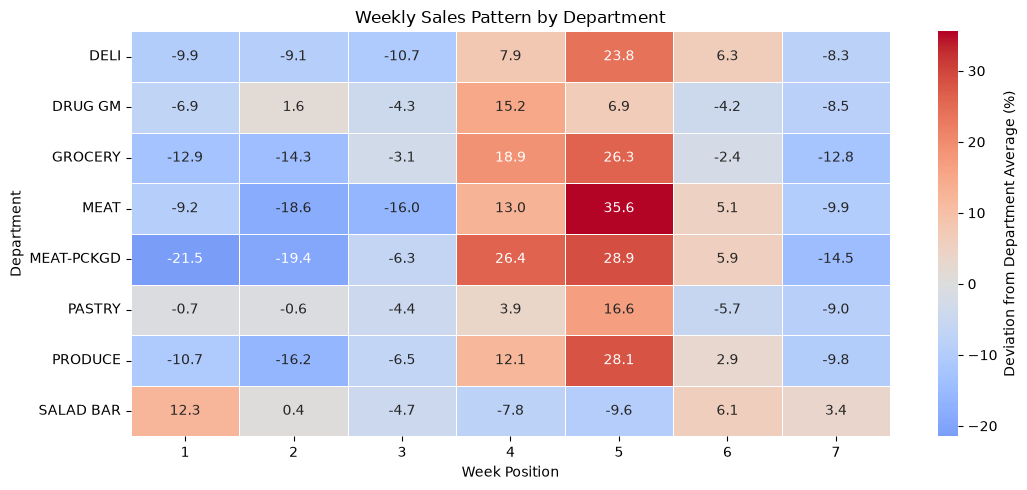

In [29]:

import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(11, 5))

sns.heatmap(
    department_weekly_matrix,
    annot=True,
    fmt=".1f",
    cmap="coolwarm",
    center=0,
    linewidths=0.5,
    cbar_kws={"label": "Deviation from Department Average (%)"},
)

plt.title("Weekly Sales Pattern by Department")
plt.xlabel("Week Position")
plt.ylabel("Department")

plt.tight_layout()
plt.show()



## 7.4 Feature Engineering

### 7.4.1 Historical Sales Features

We will create historical sales features for each product.

These features describe recent sales activity, trends, and variability.

We will calculate:

- Sales totals over different time windows.
- Rolling sales statistics.
- Recent shopping basket activity.
- Sales trends and recency.
- Seven-day cycle positions.

All features will use information available at the forecast origin.

Our prediction target will be total product sales over the next 30 days.


In [30]:
daily_product_series.head()

,PRODUCT_ID,DAY,daily_quantity,transaction_rows,daily_baskets,first_sale_day,before_first_sale
0,819765,1,0.0,0,0,11,True
1,819765,2,0.0,0,0,11,True
2,819765,3,0.0,0,0,11,True
3,819765,4,0.0,0,0,11,True
4,819765,5,0.0,0,0,11,True


In [31]:
# 1. Prepare daily product data
forecast_features = (
    daily_product_series
    .sort_values(["PRODUCT_ID", "DAY"])
    .reset_index(drop=True)
    .copy()
)

# 2. Group observations by product
product_groups = forecast_features.groupby(
    "PRODUCT_ID",
    sort=False,
)

# 3. Historical sales totals
for window in [7, 30, 60]:
    forecast_features[f"sales_last_{window}d"] = (
        product_groups["daily_quantity"]
        .transform(
            lambda x: x.rolling(
                window=window,
                min_periods=window,
            ).sum()
        )
    )

# 4. Previous 30-day sales
forecast_features["sales_prev_30d"] = (
    forecast_features
    .groupby("PRODUCT_ID")["sales_last_30d"]
    .shift(30)
)

# 5. Rolling standard deviation
forecast_features["rolling_std_30d"] = (
    product_groups["daily_quantity"]
    .transform(
        lambda x: x.rolling(
            window=30,
            min_periods=30,
        ).std()
    )
)

# 6. Active sales days in the last 30 days
forecast_features["has_sale"] = (
    forecast_features["daily_quantity"] > 0
).astype(int)

forecast_features["active_days_last_30d"] = (
    forecast_features
    .groupby("PRODUCT_ID")["has_sale"]
    .transform(
        lambda x: x.rolling(
            window=30,
            min_periods=30,
        ).sum()
    )
)

# 7. Recent shopping basket activity
forecast_features["baskets_last_30d"] = (
    product_groups["daily_baskets"]
    .transform(
        lambda x: x.rolling(
            window=30,
            min_periods=30,
        ).sum()
    )
)

# 8. Sales trend
forecast_features["sales_trend_30d"] = (
    forecast_features["sales_last_30d"]
    - forecast_features["sales_prev_30d"]
)

# 9. Days since last observed sale
last_sale_day = forecast_features["DAY"].where(
    forecast_features["daily_quantity"].gt(0)
)

last_sale_day = last_sale_day.groupby(
    forecast_features["PRODUCT_ID"]
).ffill()

forecast_features["days_since_last_sale"] = (
    forecast_features["DAY"] - last_sale_day
)

# 10. Seven-day cycle
forecast_features["week_position"] = (
    (forecast_features["DAY"] - 1) % 7
) + 1

# 11. Available product history
forecast_features["history_days"] = (
    forecast_features["DAY"]
    - forecast_features["first_sale_day"]
    + 1
)

# Remove temporary column
forecast_features = forecast_features.drop(
    columns="has_sale"
)

print("Feature Dataset Shape:", forecast_features.shape)

display(
    forecast_features.loc[
        forecast_features["PRODUCT_ID"] == 1082185
    ].tail(10).round(2)
)


Feature Dataset Shape: (324927, 18)


,PRODUCT_ID,DAY,daily_quantity,transaction_rows,daily_baskets,first_sale_day,before_first_sale,sales_last_7d,sales_last_30d,sales_last_60d,sales_prev_30d,rolling_std_30d,active_days_last_30d,baskets_last_30d,sales_trend_30d,days_since_last_sale,week_position,history_days
246707,1082185,702,32.0,32,32,1,False,359.0,1500.0,3006.0,1506.0,19.26,30.0,1444.0,-6.0,0.0,2,702
246708,1082185,703,53.0,52,52,1,False,357.0,1518.0,3059.0,1541.0,19.06,30.0,1463.0,-23.0,0.0,3,703
246709,1082185,704,54.0,51,51,1,False,351.0,1535.0,3077.0,1542.0,18.89,30.0,1477.0,-7.0,0.0,4,704
246710,1082185,705,70.0,65,65,1,False,337.0,1564.0,3095.0,1531.0,19.09,30.0,1505.0,33.0,0.0,5,705
246711,1082185,706,43.0,43,43,1,False,339.0,1559.0,3104.0,1545.0,19.15,30.0,1502.0,14.0,0.0,6,706
246712,1082185,707,47.0,46,46,1,False,347.0,1542.0,3114.0,1572.0,19.04,30.0,1485.0,-30.0,0.0,7,707
246713,1082185,708,39.0,38,38,1,False,338.0,1535.0,3100.0,1565.0,19.15,30.0,1481.0,-30.0,0.0,1,708
246714,1082185,709,50.0,50,50,1,False,356.0,1536.0,3111.0,1575.0,19.14,30.0,1483.0,-39.0,0.0,2,709
246715,1082185,710,49.0,47,47,1,False,352.0,1543.0,3116.0,1573.0,19.07,30.0,1488.0,-30.0,0.0,3,710
246716,1082185,711,60.0,56,56,1,False,358.0,1565.0,3108.0,1543.0,18.96,30.0,1506.0,22.0,0.0,4,711


In [32]:
# Historical features used for modeling
historical_feature_cols = [
    "sales_last_7d",
    "sales_last_30d",
    "sales_prev_30d",
    "sales_last_60d",
    "rolling_std_30d",
    "active_days_last_30d",
    "baskets_last_30d",
    "sales_trend_30d",
    "days_since_last_sale",
    "week_position",
]

# Keep observations with enough historical data
valid_features = forecast_features.loc[
    forecast_features["history_days"] >= 60
].copy()

# Remove rows without complete feature windows
valid_features = valid_features.dropna(
    subset=historical_feature_cols
)

# Validate results
assert valid_features[historical_feature_cols].notna().all().all()

assert np.isfinite(
    valid_features[historical_feature_cols].to_numpy()
).all()

assert valid_features["PRODUCT_ID"].nunique() == 457

print("Original Panel:", forecast_features.shape)
print("Valid Feature Dataset:", valid_features.shape)
print("Unique Products:", valid_features["PRODUCT_ID"].nunique())

print("\nFEATURE SUMMARY")

display(
    valid_features[historical_feature_cols]
    .describe()
    .round(2)
)


Original Panel: (324927, 18)
Valid Feature Dataset: (293618, 18)
Unique Products: 457

FEATURE SUMMARY


,sales_last_7d,sales_last_30d,sales_prev_30d,sales_last_60d,rolling_std_30d,active_days_last_30d,baskets_last_30d,sales_trend_30d,days_since_last_sale,week_position
count,293618.00,293618.00,293618.00,293618.00,293618.00,293618.00,293618.00,293618.00,293618.00,293618.0
mean,21.13,89.66,86.48,176.14,2.57,21.09,64.75,3.18,1.13,4.0
std,32.26,123.64,121.15,238.25,2.74,6.01,92.86,56.25,7.22,2.0
min,0.00,0.00,0.00,0.00,0.00,0.00,0.00,-931.00,0.00,1.0
25%,7.00,34.00,32.00,69.00,1.23,17.00,27.00,-12.00,0.00,2.0
50%,12.00,53.00,51.00,105.00,1.76,21.00,39.00,2.00,0.00,4.0
75%,23.00,95.00,91.00,185.00,2.88,26.00,65.00,16.00,1.00,6.0
max,634.00,1888.00,1888.00,3146.00,40.32,30.00,1602.00,1122.00,165.00,7.0



### 7.4.3 Create the 30-Day Forecast Target

We will predict total product sales over the next 30 days.

For each product and forecast origin, the target will be the sum of sales from day t+1 to day t+30.

The target will not include sales from the forecast origin.

We will keep observations only when the complete future 30-day period is available.

The final 30 days of our dataset will not have known target values.


In [33]:
# 1. Define forecasting horizon
FORECAST_HORIZON = 30

# 2. Prepare target dataset
forecast_targets = daily_product_series[
    ["PRODUCT_ID", "DAY", "daily_quantity"]
].copy()

forecast_targets = forecast_targets.sort_values(
    ["PRODUCT_ID", "DAY"]
).reset_index(drop=True)

# 3. Calculate future 30-day sales
forecast_targets["target_sales_next_30d"] = (
    forecast_targets
    .groupby("PRODUCT_ID")["daily_quantity"]
    .transform(
        lambda x: (
            x.shift(-1)
            .iloc[::-1]
            .rolling(
                window=FORECAST_HORIZON,
                min_periods=FORECAST_HORIZON,
            )
            .sum()
            .iloc[::-1]
        )
    )
)

# 4. Merge target with historical features
forecast_dataset = valid_features.merge(
    forecast_targets[
        ["PRODUCT_ID", "DAY", "target_sales_next_30d"]
    ],
    on=["PRODUCT_ID", "DAY"],
    how="left",
    validate="one_to_one",
)

# 5. Record target period end
forecast_dataset["target_end_day"] = (
    forecast_dataset["DAY"] + FORECAST_HORIZON
)

# 6. Keep observations with known targets
model_dataset = forecast_dataset.dropna(
    subset=["target_sales_next_30d"]
).copy()

# 7. Validate target
assert model_dataset["target_sales_next_30d"].ge(0).all()

assert model_dataset["target_end_day"].le(MAX_DAY).all()

assert model_dataset["PRODUCT_ID"].nunique() == 457

print("Feature Dataset:", valid_features.shape)
print("Forecast Dataset:", forecast_dataset.shape)
print("Model Dataset:", model_dataset.shape)

print(
    "Missing Target Values:",
    forecast_dataset["target_sales_next_30d"].isna().sum()
)

print("\nTARGET DISTRIBUTION")

display(
    model_dataset["target_sales_next_30d"]
    .describe(
        percentiles=[0.25, 0.50, 0.75, 0.90, 0.95, 0.99]
    )
    .round(2)
)

Feature Dataset: (293618, 18)
Forecast Dataset: (293618, 20)
Model Dataset: (279908, 20)
Missing Target Values: 13710

TARGET DISTRIBUTION


count    279908.00
mean         91.71
std         125.55
min           0.00
25%          35.00
50%          54.00
75%          97.00
90%         192.00
95%         287.00
99%         597.93
max        1888.00
Name: target_sales_next_30d, dtype: float64

In [34]:
daily_product_series.head()

,PRODUCT_ID,DAY,daily_quantity,transaction_rows,daily_baskets,first_sale_day,before_first_sale
0,819765,1,0.0,0,0,11,True
1,819765,2,0.0,0,0,11,True
2,819765,3,0.0,0,0,11,True
3,819765,4,0.0,0,0,11,True
4,819765,5,0.0,0,0,11,True


In [35]:
# Validate future target calculation
PRODUCT_ID = 1082185
FORECAST_DAY = 100

# Calculate actual future sales directly
actual_future_sales = daily_product_series.loc[
    (daily_product_series["PRODUCT_ID"] == PRODUCT_ID)
    & daily_product_series["DAY"].between(
        FORECAST_DAY + 1,
        FORECAST_DAY + FORECAST_HORIZON,
    ),
    "daily_quantity",
].sum()

# Get engineered target
engineered_target = model_dataset.loc[
    (model_dataset["PRODUCT_ID"] == PRODUCT_ID)
    & (model_dataset["DAY"] == FORECAST_DAY),
    "target_sales_next_30d",
].iloc[0]

print("Product ID:", PRODUCT_ID)
print("Forecast Origin:", FORECAST_DAY)
print("Target Period: Days 101-130")
print("Actual Future Sales:", actual_future_sales)
print("Engineered Target:", engineered_target)

# Verify target calculation
assert np.isclose(
    actual_future_sales,
    engineered_target,
)

print("\nTarget Calculation Check: PASSED")

Product ID: 1082185
Forecast Origin: 100
Target Period: Days 101-130
Actual Future Sales: 1230.0
Engineered Target: 1230.0

Target Calculation Check: PASSED



## 7.5 Time-Based Dataset Split

We will split the forecasting dataset based on time.

Our goal is to predict the next 30 days of product sales.

We will use non-overlapping 30-day target periods.

- Training targets end on or before Day 531.
- Validation targets cover Days 532–621.
- Test targets cover Days 622–711.

We will keep the same product universe across all datasets.

This approach prevents future target information from entering the training data.


In [36]:
# 1. Define forecasting boundaries
TRAIN_END_DAY = 531
VAL_END_DAY = 621
TEST_END_DAY = 711

FORECAST_HORIZON = 30

# 2. Define forecast origins
train_origins = list(
    range(111, 502, FORECAST_HORIZON)
)

val_origins = [531, 561, 591]
test_origins = [621, 651, 681]

origin_groups = {
    "Train": train_origins,
    "Validation": val_origins,
    "Test": test_origins,
}

In [38]:
# 3. Create datasets
forecast_splits = {}

for dataset_name, origins in origin_groups.items():

    subset = model_dataset.loc[
        model_dataset["DAY"].isin(origins)
    ].copy()

    subset["target_start_day"] = (
        subset["DAY"] + 1
    )

    subset["dataset"] = dataset_name

    forecast_splits[dataset_name] = subset

# 4. Extract individual datasets
forecast_train = forecast_splits["Train"]
forecast_val = forecast_splits["Validation"]
forecast_test = forecast_splits["Test"]

# 5. Validate time boundaries
assert (
    forecast_train["target_end_day"] <= TRAIN_END_DAY
).all()

assert (
    forecast_val["target_start_day"] > TRAIN_END_DAY
).all()

assert (
    forecast_val["target_end_day"] <= VAL_END_DAY
).all()

assert (
    forecast_test["target_start_day"] > VAL_END_DAY
).all()

assert (
    forecast_test["target_end_day"] <= TEST_END_DAY
).all()


In [39]:
# 6. Validate unique product-origin pairs
for name, dataset in forecast_splits.items():
    assert not dataset.duplicated(
        ["PRODUCT_ID", "DAY"]
    ).any()

    assert dataset["target_sales_next_30d"].notna().all()

In [40]:
# 7. Create dataset summary
split_summary = pd.DataFrame([
    {
        "dataset": name,
        "rows": len(dataset),
        "products": dataset["PRODUCT_ID"].nunique(),
        "forecast_origins": dataset["DAY"].nunique(),
        "first_origin": dataset["DAY"].min(),
        "last_origin": dataset["DAY"].max(),
        "target_mean": dataset["target_sales_next_30d"].mean(),
        "target_median": dataset["target_sales_next_30d"].median(),
    }
    for name, dataset in forecast_splits.items()
])

print("TIME-BASED DATASET DISTRIBUTION")

display(split_summary.round(2))

TIME-BASED DATASET DISTRIBUTION


,dataset,rows,products,forecast_origins,first_origin,last_origin,target_mean,target_median
0,Train,6378,457,14,111,501,93.53,55.0
1,Validation,1371,457,3,531,591,84.61,52.0
2,Test,1371,457,3,621,681,91.00,53.0



## 7.6 Baseline Demand Forecasting

We will create simple forecasting models before training machine learning algorithms.

Our baseline models are:

1. Last 30 Days
2. Last 60-Day Average

We will evaluate the models using:

- MAE
- RMSE
- WAPE
- Bias

Validation data will be used to compare the baseline methods.

The test dataset will remain untouched during model development.


In [42]:
# 1. Prepare validation dataset
baseline_val = forecast_val.copy()

# 2. Last 30 Days Baseline
baseline_val["pred_last_30d"] = (
    baseline_val["sales_last_30d"]
)

# 3. Last 60-Day Average Baseline
baseline_val["pred_avg_60d"] = (
    baseline_val["sales_last_60d"] / 2
)

# 4. Validate predictions
prediction_cols = [
    "pred_last_30d",
    "pred_avg_60d",
]

assert baseline_val[prediction_cols].notna().all().all()

assert baseline_val[prediction_cols].ge(0).all().all()

# Check consistency of historical sales features
assert np.allclose(
    baseline_val["sales_last_60d"],
    baseline_val["sales_last_30d"]
    + baseline_val["sales_prev_30d"],
)

# 5. Display baseline predictions
display(
    baseline_val[
        [
            "PRODUCT_ID",
            "DAY",
            "target_sales_next_30d",
            "pred_last_30d",
            "pred_avg_60d",
        ]
    ].head(10).round(2)
)

,PRODUCT_ID,DAY,target_sales_next_30d,pred_last_30d,pred_avg_60d
461,819765,531,24.0,38.0,38.0
491,819765,561,24.0,24.0,31.0
521,819765,591,31.0,24.0,24.0
1108,819927,531,37.0,39.0,29.5
1138,819927,561,29.0,37.0,38.0
1168,819927,591,30.0,29.0,33.0
1753,819978,531,21.0,14.0,21.0
1783,819978,561,61.0,21.0,17.5
1813,819978,591,19.0,61.0,41.0
2403,820165,531,52.0,14.0,17.0


In [43]:
def evaluate_forecast(y_true, y_pred):
    """Calculate regression forecasting metrics."""

    actual = np.asarray(y_true, dtype=float)
    predicted = np.asarray(y_pred, dtype=float)

    if actual.shape != predicted.shape:
        raise ValueError("Actual and predicted shapes must match.")

    if not np.isfinite(actual).all():
        raise ValueError("Actual values must be finite.")

    if not np.isfinite(predicted).all():
        raise ValueError("Predicted values must be finite.")

    # Calculate forecast errors
    errors = predicted - actual

    # Calculate evaluation metrics
    mae = mean_absolute_error(actual, predicted)

    rmse = np.sqrt(
        mean_squared_error(actual, predicted)
    )

    actual_total = np.abs(actual).sum()

    wape = (
        np.abs(errors).sum() / actual_total * 100
        if actual_total > 0 else np.nan
    )

    bias = errors.mean()

    bias_pct = (
        errors.sum() / actual_total * 100
        if actual_total > 0 else np.nan
    )

    return {
        "MAE": mae,
        "RMSE": rmse,
        "WAPE (%)": wape,
        "Bias": bias,
        "Bias (%)": bias_pct,
    }


In [44]:
# 1. Define baseline models
baseline_models = {
    "Last 30 Days": "pred_last_30d",
    "Last 60-Day Average": "pred_avg_60d",
}

# 2. Evaluate each model
baseline_results = []

for model_name, prediction_col in baseline_models.items():

    metrics = evaluate_forecast(
        y_true=baseline_val["target_sales_next_30d"],
        y_pred=baseline_val[prediction_col],
    )

    baseline_results.append({
        "model": model_name,
        **metrics,
    })

# 3. Create model comparison
baseline_comparison = (
    pd.DataFrame(baseline_results)
    .set_index("model")
    .sort_values("MAE")
)

print("BASELINE FORECAST COMPARISON")

display(baseline_comparison.round(3))

BASELINE FORECAST COMPARISON


,MAE,RMSE,WAPE (%),Bias,Bias (%)
model,,,,,
Last 30 Days,28.806,57.780,34.045,3.586,4.239
Last 60-Day Average,28.894,60.504,34.148,6.141,7.258


In [45]:

# Compare actual and predicted quantities by period
baseline_period_summary = (
    baseline_val
    .groupby("DAY")
    .agg(
        actual_total=("target_sales_next_30d", "sum"),
        last_30d_total=("pred_last_30d", "sum"),
        avg_60d_total=("pred_avg_60d", "sum"),
    )
    .reset_index()
)

baseline_period_summary["target_end_day"] = (
    baseline_period_summary["DAY"] + FORECAST_HORIZON
)

display(baseline_period_summary.round(2))


,DAY,actual_total,last_30d_total,avg_60d_total,target_end_day
0,531,39167.0,44827.0,44379.0,561
1,561,36927.0,39167.0,41997.0,591
2,591,39910.0,36927.0,38047.0,621



## 7.7 XGBoost Demand Forecasting

We will train a global XGBoost regression model to predict the next 30 days of product sales.

The model will use:

- Historical sales features
- Recent sales trends
- Product and category information
- Weekly sales patterns

We will use One-Hot Encoding for categorical features.

Model performance will be evaluated using validation data.

We will compare XGBoost with our baseline forecasting models.


In [47]:
# 1. Define categorical features
categorical_cols = [
    "PRODUCT_ID",
    "DEPARTMENT",
    "COMMODITY_DESC",
]

numeric_cols = historical_feature_cols.copy()

feature_cols = numeric_cols + categorical_cols

# 2. Prepare product metadata
product_metadata = eligible_product_lookup[
    ["PRODUCT_ID", "DEPARTMENT", "COMMODITY_DESC"]
].copy()

assert product_metadata["PRODUCT_ID"].is_unique

# 3. Add product metadata to training and validation
forecast_train_ml = forecast_train.merge(
    product_metadata,
    on="PRODUCT_ID",
    how="left",
    validate="many_to_one",
)

forecast_val_ml = forecast_val.merge(
    product_metadata,
    on="PRODUCT_ID",
    how="left",
    validate="many_to_one",
)

# 4. Prepare categorical values
for dataset in [forecast_train_ml, forecast_val_ml]:
    dataset["PRODUCT_ID"] = dataset["PRODUCT_ID"].astype(str)

    for col in ["DEPARTMENT", "COMMODITY_DESC"]:
        dataset[col] = dataset[col].fillna("UNKNOWN").astype(str)

# 5. Create model inputs and targets
X_forecast_train = forecast_train_ml[feature_cols].copy()
X_forecast_val = forecast_val_ml[feature_cols].copy()

y_forecast_train = forecast_train_ml[
    "target_sales_next_30d"
].copy()

y_forecast_val = forecast_val_ml[
    "target_sales_next_30d"
].copy()

# 6. Validate datasets
assert X_forecast_train.columns.equals(
    X_forecast_val.columns
)

assert X_forecast_train[numeric_cols].notna().all().all()
assert X_forecast_val[numeric_cols].notna().all().all()

print("Training Features:", X_forecast_train.shape)
print("Validation Features:", X_forecast_val.shape)
print("Numeric Features:", len(numeric_cols))
print("Categorical Features:", len(categorical_cols))

Training Features: (6378, 13)
Validation Features: (1371, 13)
Numeric Features: 10
Categorical Features: 3


In [48]:
# 1. Define preprocessing
forecast_preprocessor = ColumnTransformer(
    transformers=[
        ("numeric", "passthrough", numeric_cols),
        (
            "categorical",
            OneHotEncoder(handle_unknown="ignore"),
            categorical_cols,
        ),
    ],
    remainder="drop",
)

# 2. Initialize XGBoost
xgb_regressor = XGBRegressor(
    objective="reg:squarederror",
    n_estimators=300,
    learning_rate=0.05,
    max_depth=4,
    min_child_weight=5,
    subsample=0.85,
    colsample_bytree=0.85,
    reg_lambda=1.0,
    tree_method="hist",
    eval_metric="mae",
    random_state=42,
    n_jobs=4,
)

# 3. Create preprocessing and model pipeline
xgb_forecast_pipeline = Pipeline(
    steps=[
        ("preprocessing", forecast_preprocessor),
        ("model", xgb_regressor),
    ]
)

# 4. Train model
xgb_forecast_pipeline.fit(
    X_forecast_train,
    y_forecast_train,
)

# 5. Predict validation demand
xgb_val_predictions = xgb_forecast_pipeline.predict(
    X_forecast_val
)

# 6. Ensure non-negative sales predictions
xgb_val_predictions = np.clip(
    xgb_val_predictions,
    a_min=0,
    a_max=None,
)

print("XGBoost model trained successfully.")
print("Validation Predictions:", len(xgb_val_predictions))

XGBoost model trained successfully.
Validation Predictions: 1371


In [49]:

# Evaluate XGBoost
xgb_metrics = evaluate_forecast(
    y_true=y_forecast_val,
    y_pred=xgb_val_predictions,
)

xgb_evaluation = pd.DataFrame(
    [xgb_metrics],
    index=["XGBoost"],
)

# Compare XGBoost with baseline models
forecast_model_comparison = pd.concat([
    baseline_comparison,
    xgb_evaluation,
]).sort_values("MAE")

print("FORECAST MODEL COMPARISON")

display(forecast_model_comparison.round(3))


FORECAST MODEL COMPARISON


,MAE,RMSE,WAPE (%),Bias,Bias (%)
Last 30 Days,28.806,57.780,34.045,3.586,4.239
Last 60-Day Average,28.894,60.504,34.148,6.141,7.258
XGBoost,29.167,60.653,34.472,7.498,8.861



## 7.8 LightGBM Demand Forecasting

We will train a global LightGBM regression model.

The model will use the same features and datasets as XGBoost.

We will evaluate the model using MAE, RMSE, WAPE, and Bias.

Our goal is to compare LightGBM with XGBoost and the baseline forecasting methods.

The test dataset will not be used during model development.


In [51]:
# 1. Initialize LightGBM
lgbm_regressor = lgb.LGBMRegressor(
    objective="regression",
    n_estimators=300,
    learning_rate=0.05,
    num_leaves=15,
    max_depth=-1,
    min_child_samples=40,
    subsample=0.85,
    subsample_freq=1,
    colsample_bytree=0.85,
    reg_lambda=1.0,
    random_state=42,
    n_jobs=4,
    verbosity=-1,
)

# 2. Create pipeline
lgbm_forecast_pipeline = Pipeline(
    steps=[
        ("preprocessing", clone(forecast_preprocessor)),
        ("model", lgbm_regressor),
    ]
)

# 3. Train LightGBM
lgbm_forecast_pipeline.fit(
    X_forecast_train,
    y_forecast_train,
)

# 4. Predict validation demand
lgbm_val_predictions = lgbm_forecast_pipeline.predict(
    X_forecast_val
)

# 5. Prevent negative forecasts
lgbm_val_predictions = np.clip(
    lgbm_val_predictions,
    a_min=0,
    a_max=None,
)

print("LightGBM trained successfully.")
print("Validation Predictions:", len(lgbm_val_predictions))

LightGBM trained successfully.
Validation Predictions: 1371


In [52]:

# 1. Evaluate LightGBM
lgbm_metrics = evaluate_forecast(
    y_true=y_forecast_val,
    y_pred=lgbm_val_predictions,
)

lgbm_evaluation = pd.DataFrame(
    [lgbm_metrics],
    index=["LightGBM"],
)

# 2. Compare all models
forecast_model_comparison = pd.concat([
    baseline_comparison,
    xgb_evaluation,
    lgbm_evaluation,
]).sort_values("MAE")

print("FORECAST MODEL COMPARISON")

display(forecast_model_comparison.round(3))


FORECAST MODEL COMPARISON


,MAE,RMSE,WAPE (%),Bias,Bias (%)
Last 30 Days,28.806,57.780,34.045,3.586,4.239
LightGBM,28.876,57.338,34.128,6.642,7.850
Last 60-Day Average,28.894,60.504,34.148,6.141,7.258
XGBoost,29.167,60.653,34.472,7.498,8.861


In [53]:
# Create validation prediction dataset
lgbm_validation_results = forecast_val[
    ["PRODUCT_ID", "DAY", "target_sales_next_30d"]
].copy()

lgbm_validation_results["lgbm_prediction"] = (
    lgbm_val_predictions
)

# Aggregate predictions by forecast origin
lgbm_period_summary = (
    lgbm_validation_results
    .groupby("DAY")
    .agg(
        actual_total=("target_sales_next_30d", "sum"),
        predicted_total=("lgbm_prediction", "sum"),
    )
    .reset_index()
)

# Calculate percentage error
lgbm_period_summary["total_error_pct"] = (
    (
        lgbm_period_summary["predicted_total"]
        / lgbm_period_summary["actual_total"]
        - 1
    ) * 100
)

display(lgbm_period_summary.round(2))

,DAY,actual_total,predicted_total,total_error_pct
0,531,39167.0,46526.68,18.79
1,561,36927.0,40091.69,8.57
2,591,39910.0,38491.81,-3.55



### 7.8.3 Log-Transformed Target Experiment

The target variable has a right-skewed distribution.

We will train a second LightGBM model using a log1p target transformation.

The model predictions will be converted back to the original sales scale using expm1.

We will compare both models on the validation dataset using MAE, RMSE, WAPE, and Bias.

We will not use StandardScaler because LightGBM is a tree-based model.


In [55]:
# 1. Create LightGBM with log-transformed target
lgbm_log_pipeline = TransformedTargetRegressor(
    regressor=clone(lgbm_forecast_pipeline),
    func=np.log1p,
    inverse_func=np.expm1,
)

# 2. Train the model
lgbm_log_pipeline.fit(
    X_forecast_train,
    y_forecast_train,
)

# 3. Predict on the original sales scale
lgbm_log_predictions = lgbm_log_pipeline.predict(
    X_forecast_val
)

# 4. Prevent negative predictions
lgbm_log_predictions = np.clip(
    lgbm_log_predictions,
    a_min=0,
    a_max=None,
)

# 5. Evaluate the model
lgbm_log_metrics = evaluate_forecast(
    y_true=y_forecast_val,
    y_pred=lgbm_log_predictions,
)

lgbm_log_evaluation = pd.DataFrame(
    [lgbm_log_metrics],
    index=["LightGBM + Log Target"],
)

# 6. Compare with previous models
log_comparison = pd.concat([
    baseline_comparison,
    xgb_evaluation,
    lgbm_evaluation,
    lgbm_log_evaluation,
]).sort_values("MAE")

print("LOG TRANSFORMATION EXPERIMENT")

display(log_comparison.round(3))

LOG TRANSFORMATION EXPERIMENT


,MAE,RMSE,WAPE (%),Bias,Bias (%)
LightGBM + Log Target,27.599,56.128,32.618,0.241,0.285
Last 30 Days,28.806,57.780,34.045,3.586,4.239
LightGBM,28.876,57.338,34.128,6.642,7.850
Last 60-Day Average,28.894,60.504,34.148,6.141,7.258
XGBoost,29.167,60.653,34.472,7.498,8.861



### 7.8.4 XGBoost Log-Target Experiment

We will apply the same log1p target transformation to XGBoost.

Our goal is to compare XGBoost and LightGBM under the same conditions.

Both models will use the same training features and validation dataset.

We will compare MAE, RMSE, WAPE, and Bias before starting hyperparameter optimization.


In [56]:
# 1. Create XGBoost with log-transformed target
xgb_log_pipeline = TransformedTargetRegressor(
    regressor=clone(xgb_forecast_pipeline),
    func=np.log1p,
    inverse_func=np.expm1,
)

# 2. Train the model
xgb_log_pipeline.fit(
    X_forecast_train,
    y_forecast_train,
)

# 3. Generate validation predictions
xgb_log_predictions = xgb_log_pipeline.predict(
    X_forecast_val
)

# 4. Prevent negative sales predictions
xgb_log_predictions = np.clip(
    xgb_log_predictions,
    a_min=0,
    a_max=None,
)

# 5. Calculate evaluation metrics
xgb_log_metrics = evaluate_forecast(
    y_true=y_forecast_val,
    y_pred=xgb_log_predictions,
)

xgb_log_evaluation = pd.DataFrame(
    [xgb_log_metrics],
    index=["XGBoost + Log Target"],
)

# 6. Compare all forecasting models
forecast_comparison = pd.concat([
    baseline_comparison,
    xgb_evaluation,
    xgb_log_evaluation,
    lgbm_evaluation,
    lgbm_log_evaluation,
]).sort_values("MAE")

print("FINAL BASELINE MODEL COMPARISON")

display(forecast_comparison.round(3))

FINAL BASELINE MODEL COMPARISON


,MAE,RMSE,WAPE (%),Bias,Bias (%)
XGBoost + Log Target,26.620,53.563,31.461,-0.060,-0.071
LightGBM + Log Target,27.599,56.128,32.618,0.241,0.285
Last 30 Days,28.806,57.780,34.045,3.586,4.239
LightGBM,28.876,57.338,34.128,6.642,7.850
Last 60-Day Average,28.894,60.504,34.148,6.141,7.258
XGBoost,29.167,60.653,34.472,7.498,8.861



## 7.9 XGBoost Hyperparameter Optimization

We will optimize the XGBoost model using Optuna.

The model will continue using the log1p target transformation.

We will use rolling time-based validation within the training dataset.

Our objective is to minimize MAE on the original sales scale.

The external validation and final test datasets will not be used during hyperparameter search.


In [58]:
# Define internal validation origins
cv_origins = [351, 411, 471]

def objective_xgb(trial):
    """Minimize rolling validation MAE for XGBoost."""

    # 1. Define hyperparameter search space
    params = {
        "n_estimators": trial.suggest_int(
            "n_estimators", 150, 450, step=50
        ),
        "learning_rate": trial.suggest_float(
            "learning_rate", 0.02, 0.10, log=True
        ),
        "max_depth": trial.suggest_int(
            "max_depth", 2, 6
        ),
        "min_child_weight": trial.suggest_int(
            "min_child_weight", 2, 12
        ),
        "subsample": trial.suggest_float(
            "subsample", 0.70, 1.0, step=0.05
        ),
        "colsample_bytree": trial.suggest_float(
            "colsample_bytree", 0.70, 1.0, step=0.05
        ),
        "reg_lambda": trial.suggest_float(
            "reg_lambda", 0.1, 10.0, log=True
        ),
    }

    fold_scores = []

    # 2. Rolling time-based validation
    for origin in cv_origins:

        train_mask = (
            forecast_train_ml["target_end_day"] <= origin
        )

        val_mask = (
            forecast_train_ml["DAY"] == origin
        )

        # Validate temporal ordering
        assert train_mask.any() and val_mask.any()

        # 3. Clone the log-target pipeline
        model = clone(xgb_log_pipeline)

        # 4. Apply trial parameters
        model.set_params(
            **{
                f"regressor__model__{key}": value
                for key, value in params.items()
            }
        )

        # 5. Train on historical observations
        model.fit(
            X_forecast_train.loc[train_mask],
            y_forecast_train.loc[train_mask],
        )

        # 6. Predict the validation period
        predictions = model.predict(
            X_forecast_train.loc[val_mask]
        )

        predictions = np.clip(predictions, 0, None)

        # 7. Calculate fold MAE
        fold_mae = mean_absolute_error(
            y_forecast_train.loc[val_mask],
            predictions,
        )

        fold_scores.append(fold_mae)

    
    # 8. Minimize average MAE across folds
    return float(np.mean(fold_scores))

In [59]:
# Hide Optuna information messages
optuna.logging.set_verbosity(optuna.logging.WARNING)

# 1. Create study
forecast_xgb_study = optuna.create_study(
    direction="minimize",
    sampler=optuna.samplers.TPESampler(seed=42),
)

# 2. Evaluate the existing model parameters first
forecast_xgb_study.enqueue_trial({
    "n_estimators": 300,
    "learning_rate": 0.05,
    "max_depth": 4,
    "min_child_weight": 5,
    "subsample": 0.85,
    "colsample_bytree": 0.85,
    "reg_lambda": 1.0,
})

# 3. Run optimization
forecast_xgb_study.optimize(
    objective_xgb,
    n_trials=20,
    show_progress_bar=False,
)

# 4. Display results
print("INITIAL CV MAE")
print(round(forecast_xgb_study.trials[0].value, 4))

print("\nBEST CV MAE")
print(round(forecast_xgb_study.best_value, 4))

print("\nBEST HYPERPARAMETERS")
for name, value in forecast_xgb_study.best_params.items():
    print(f"{name}: {value}")

# 5. Show trial results
forecast_xgb_trials = forecast_xgb_study.trials_dataframe()

display(
    forecast_xgb_trials[
        ["number", "value", "params_n_estimators",
         "params_learning_rate", "params_max_depth",
         "params_min_child_weight", "params_reg_lambda"]
    ]
    .sort_values("value")
    .head(10)
    .round(4)
)

INITIAL CV MAE
26.9078

BEST CV MAE
26.4656

BEST HYPERPARAMETERS
n_estimators: 150
learning_rate: 0.08642068036189747
max_depth: 3
min_child_weight: 9
subsample: 0.7999999999999999
colsample_bytree: 0.85
reg_lambda: 1.2399967836846095


,number,value,params_n_estimators,params_learning_rate,params_max_depth,params_min_child_weight,params_reg_lambda
7,7,26.4656,150,0.0864,3,9,1.2400
11,11,26.7383,350,0.0251,5,6,2.6674
19,19,26.7828,400,0.0221,5,3,2.5646
14,14,26.8160,200,0.0534,3,10,3.8971
18,18,26.8175,400,0.0231,5,9,4.4168
12,12,26.8978,150,0.0335,4,6,1.9642
5,5,26.8994,350,0.0216,5,3,8.5362
0,0,26.9078,300,0.0500,4,5,1.0000
6,6,26.9688,400,0.0327,2,9,0.9780
10,10,26.9861,200,0.0982,4,4,4.3656



### 7.9.2 Optimized XGBoost Evaluation

Optuna improved the internal cross-validation MAE from 26.9078 to 26.4656.

We will train XGBoost using the best hyperparameters.

The model will use the log1p target transformation.

We will evaluate the optimized model on the external validation dataset and compare it with previous models.

The test dataset will remain untouched.


In [60]:
# 1. Get best Optuna parameters
best_xgb_params = forecast_xgb_study.best_params.copy()

# 2. Create an independent copy of the existing model
xgb_tuned_pipeline = clone(xgb_log_pipeline)

# 3. Apply optimized hyperparameters
xgb_tuned_pipeline.set_params(
    **{
        f"regressor__model__{key}": value
        for key, value in best_xgb_params.items()
    }
)

# 4. Train on the full training dataset
xgb_tuned_pipeline.fit(
    X_forecast_train,
    y_forecast_train,
)

# 5. Predict validation sales
xgb_tuned_predictions = xgb_tuned_pipeline.predict(
    X_forecast_val
)

# 6. Prevent negative sales predictions
xgb_tuned_predictions = np.clip(
    xgb_tuned_predictions,
    0,
    None,
)

# 7. Validate predictions
assert len(xgb_tuned_predictions) == len(y_forecast_val)
assert np.isfinite(xgb_tuned_predictions).all()

print("Optimized XGBoost trained successfully.")
print("Validation Predictions:", len(xgb_tuned_predictions))

Optimized XGBoost trained successfully.
Validation Predictions: 1371


In [61]:

# 1. Evaluate optimized XGBoost
xgb_tuned_metrics = evaluate_forecast(
    y_true=y_forecast_val,
    y_pred=xgb_tuned_predictions,
)

xgb_tuned_evaluation = pd.DataFrame(
    [xgb_tuned_metrics],
    index=["XGBoost + Log Target + Optuna"],
)

# 2. Compare all forecasting models
optimized_comparison = pd.concat([
    baseline_comparison,
    xgb_evaluation,
    xgb_log_evaluation,
    lgbm_evaluation,
    lgbm_log_evaluation,
    xgb_tuned_evaluation,
]).sort_values("MAE")

print("OPTIMIZED FORECAST MODEL COMPARISON")

display(optimized_comparison.round(3))

# 3. Calculate improvement over previous XGBoost
previous_mae = xgb_log_evaluation.loc[
    "XGBoost + Log Target", "MAE"
]

optimized_mae = xgb_tuned_evaluation.loc[
    "XGBoost + Log Target + Optuna", "MAE"
]

improvement_pct = (
    (previous_mae - optimized_mae)
    / previous_mae
    * 100
)

print(f"\nValidation MAE Improvement: {improvement_pct:.2f}%")


OPTIMIZED FORECAST MODEL COMPARISON


,MAE,RMSE,WAPE (%),Bias,Bias (%)
XGBoost + Log Target,26.620,53.563,31.461,-0.060,-0.071
XGBoost + Log Target + Optuna,26.834,54.568,31.714,-0.390,-0.461
LightGBM + Log Target,27.599,56.128,32.618,0.241,0.285
Last 30 Days,28.806,57.780,34.045,3.586,4.239
LightGBM,28.876,57.338,34.128,6.642,7.850
Last 60-Day Average,28.894,60.504,34.148,6.141,7.258
XGBoost,29.167,60.653,34.472,7.498,8.861



Validation MAE Improvement: -0.80%



## 7.10 Global Multivariate LSTM

### 7.10.1 Sequence Preparation

We will create a global LSTM model using daily product sales data.

Each input sequence will contain 60 days of historical information.

The model will predict total sales for the next 30 days.

We will use four daily features:

- Log-transformed sales quantity
- Log-transformed basket count
- Weekly sine component
- Weekly cosine component

We will preserve the existing time-based train, validation, and test splits.

Feature scaling will be fitted using training data only.


In [63]:
daily_product_series.head()

,PRODUCT_ID,DAY,daily_quantity,transaction_rows,daily_baskets,first_sale_day,before_first_sale
0,819765,1,0.0,0,0,11,True
1,819765,2,0.0,0,0,11,True
2,819765,3,0.0,0,0,11,True
3,819765,4,0.0,0,0,11,True
4,819765,5,0.0,0,0,11,True


In [64]:
# 1. Define sequence parameters
SEQUENCE_LENGTH = 60

# 2. Prepare daily observations
lstm_daily = daily_product_series[
    ["PRODUCT_ID", "DAY", "daily_quantity", "daily_baskets"]
].copy()


# 3. Apply logarithmic transformations
lstm_daily["log_daily_quantity"] = np.log1p(
    lstm_daily["daily_quantity"]
)

lstm_daily["log_daily_baskets"] = np.log1p(
    lstm_daily["daily_baskets"]
)

# 4. Create cyclical weekly features
weekly_angle = (
    2 * np.pi * (lstm_daily["DAY"] - 1) / 7
)

lstm_daily["week_sin"] = np.sin(weekly_angle)
lstm_daily["week_cos"] = np.cos(weekly_angle)

# 5. Define sequence features
lstm_feature_cols = [
    "log_daily_quantity",
    "log_daily_baskets",
    "week_sin",
    "week_cos",
]

# 6. Create product-level daily arrays
product_sequence_data = {}

for product_id, group in lstm_daily.groupby("PRODUCT_ID"):

    group = group.sort_values("DAY")

    assert np.array_equal(
        group["DAY"].to_numpy(),
        np.arange(1, MAX_DAY + 1),
    )

    product_sequence_data[int(product_id)] = (
        group[lstm_feature_cols].to_numpy(
            dtype=np.float32
        )
    )

print("Products:", len(product_sequence_data))
print("Sequence Features:", lstm_feature_cols)
print("Sequence Length:", SEQUENCE_LENGTH)

Products: 457
Sequence Features: ['log_daily_quantity', 'log_daily_baskets', 'week_sin', 'week_cos']
Sequence Length: 60


In [65]:
def create_lstm_sequences(dataset):
    """Create historical sequences for demand forecasting."""

    sequences = []

    for product_id, origin in dataset[
        ["PRODUCT_ID", "DAY"]
    ].itertuples(index=False, name=None):

        product_array = product_sequence_data[int(product_id)]

        # Last 60 days, including the forecast origin
        start = int(origin) - SEQUENCE_LENGTH
        end = int(origin)

        if start < 0:
            raise ValueError("Insufficient sequence history.")

        sequence = product_array[start:end]

        if sequence.shape != (
            SEQUENCE_LENGTH,
            len(lstm_feature_cols),
        ):
            raise ValueError("Invalid sequence shape.")

        sequences.append(sequence)

    X = np.stack(sequences).astype(np.float32)

    y = dataset[
        "target_sales_next_30d"
    ].to_numpy(dtype=np.float32)

    return X, y

In [66]:
# Create the same temporal splits as XGBoost
X_lstm_train, y_lstm_train = create_lstm_sequences(
    forecast_train
)

X_lstm_val, y_lstm_val = create_lstm_sequences(
    forecast_val
)

X_lstm_test, y_lstm_test = create_lstm_sequences(
    forecast_test
)

print("Training:", X_lstm_train.shape, y_lstm_train.shape)
print("Validation:", X_lstm_val.shape, y_lstm_val.shape)
print("Test:", X_lstm_test.shape, y_lstm_test.shape)

Training: (6378, 60, 4) (6378,)
Validation: (1371, 60, 4) (1371,)
Test: (1371, 60, 4) (1371,)


In [67]:
# 1. Initialize scaler
lstm_scaler = StandardScaler()

n_features = len(lstm_feature_cols)

# 2. Fit scaler using training sequences only
lstm_scaler.fit(
    X_lstm_train.reshape(-1, n_features)
)

StandardScaler()

In [68]:
# 3. Transform all datasets
def scale_sequences(X, scaler):
    original_shape = X.shape

    X_scaled = scaler.transform(
        X.reshape(-1, original_shape[-1])
    )

    return X_scaled.reshape(
        original_shape
    ).astype(np.float32)

In [69]:
X_lstm_train_scaled = scale_sequences(
    X_lstm_train, lstm_scaler
)

X_lstm_val_scaled = scale_sequences(
    X_lstm_val, lstm_scaler
)

X_lstm_test_scaled = scale_sequences(
    X_lstm_test, lstm_scaler
)

# 4. Validate results
assert np.isfinite(X_lstm_train_scaled).all()
assert np.isfinite(X_lstm_val_scaled).all()
assert np.isfinite(X_lstm_test_scaled).all()

print("Training Shape:", X_lstm_train_scaled.shape)
print("Validation Shape:", X_lstm_val_scaled.shape)
print("Test Shape:", X_lstm_test_scaled.shape)

print("\nScaled Feature Means:")
print(X_lstm_train_scaled.mean(axis=(0, 1)).round(3))

print("\nScaled Feature Standard Deviations:")
print(X_lstm_train_scaled.std(axis=(0, 1)).round(3))

Training Shape: (6378, 60, 4)
Validation Shape: (1371, 60, 4)
Test Shape: (1371, 60, 4)

Scaled Feature Means:
[-0.  0. -0.  0.]

Scaled Feature Standard Deviations:
[1.    1.001 1.    1.   ]


In [71]:
# 1. Set random seed
tf.keras.utils.set_random_seed(42)

# 2. Transform target variables
y_lstm_train_log = np.log1p(y_lstm_train)
y_lstm_val_log = np.log1p(y_lstm_val)

# 3. Build the LSTM architecture
lstm_model = keras.Sequential([
    layers.Input(shape=(SEQUENCE_LENGTH, len(lstm_feature_cols))),

    layers.LSTM(
        units=64,
        return_sequences=False,
    ),

    layers.Dropout(0.20),

    layers.Dense(
        units=32,
        activation="relu",
    ),

    layers.Dense(units=1),
])

# 4. Compile model
lstm_model.compile(
    optimizer=keras.optimizers.Adam(learning_rate=0.001),
    loss="mse",
    metrics=["mae"],
)

# 5. Display architecture
lstm_model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ lstm (LSTM)                     │ (None, 64)             │        17,664 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │            33 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 19,777 (77.25 KB)

 Trainable params: 19,777 (77.25 KB)

 Non-trainable params: 0 (0.00 B)

In [72]:
# 1. Create model directory
model_dir = PROJECT_ROOT / "models"
model_dir.mkdir(parents=True, exist_ok=True)

# 2. Define callbacks
lstm_callbacks = [
    keras.callbacks.EarlyStopping(
        monitor="val_loss",
        patience=10,
        restore_best_weights=True,
        mode="min",
        verbose=1,
    ),

    keras.callbacks.ModelCheckpoint(
        filepath=str(model_dir / "demand_lstm_candidate.keras"),
        monitor="val_loss",
        save_best_only=True,
        mode="min",
        verbose=0,
    ),
]

# 3. Train LSTM
lstm_history = lstm_model.fit(
    X_lstm_train_scaled,
    y_lstm_train_log,
    validation_data=(
        X_lstm_val_scaled,
        y_lstm_val_log,
    ),
    epochs=60,
    batch_size=64,
    callbacks=lstm_callbacks,
    shuffle=True,
    verbose=1,
)

print("Training Completed.")

print(
    "Best Epoch:",
    np.argmin(lstm_history.history["val_loss"]) + 1
)

print(
    "Best Validation Loss:",
    round(min(lstm_history.history["val_loss"]), 4)
)


Epoch 1/60
100/100 ━━━━━━━━━━━━━━━━━━━━ 3s 17ms/step - loss: 2.8642 - mae: 1.1354 - val_loss: 0.5464 - val_mae: 0.4618
Epoch 2/60
100/100 ━━━━━━━━━━━━━━━━━━━━ 2s 15ms/step - loss: 0.3971 - mae: 0.4855 - val_loss: 0.4881 - val_mae: 0.4422
Epoch 3/60
100/100 ━━━━━━━━━━━━━━━━━━━━ 1s 14ms/step - loss: 0.3537 - mae: 0.4539 - val_loss: 0.4703 - val_mae: 0.4286
Epoch 4/60
100/100 ━━━━━━━━━━━━━━━━━━━━ 2s 17ms/step - loss: 0.3308 - mae: 0.4356 - val_loss: 0.4580 - val_mae: 0.4100
Epoch 5/60
100/100 ━━━━━━━━━━━━━━━━━━━━ 2s 21ms/step - loss: 0.2953 - mae: 0.4049 - val_loss: 0.4825 - val_mae: 0.4668
Epoch 6/60
100/100 ━━━━━━━━━━━━━━━━━━━━ 2s 16ms/step - loss: 0.2921 - mae: 0.4004 - val_loss: 0.4415 - val_mae: 0.4122
Epoch 7/60
100/100 ━━━━━━━━━━━━━━━━━━━━ 2s 16ms/step - loss: 0.2726 - mae: 0.3911 - val_loss: 0.4294 - val_mae: 0.4000
Epoch 8/60
100/100 ━━━━━━━━━━━━━━━━━━━━ 1s 14ms/step - loss: 0.2780 - mae: 0.3924 - val_loss: 0.4256 - val_mae: 0.3902
Epoch 9/60
100/100 ━━━━━━━━━━━━━━━━━━━━ 1s 14ms/

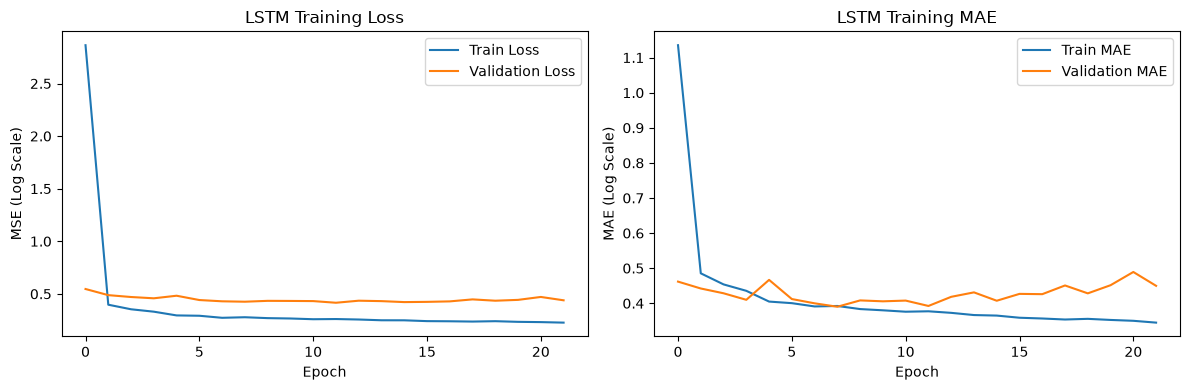

In [73]:

# Visualize model training history
history_df = pd.DataFrame(lstm_history.history)

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

# Loss
axes[0].plot(history_df["loss"], label="Train Loss")
axes[0].plot(history_df["val_loss"], label="Validation Loss")
axes[0].set_title("LSTM Training Loss")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("MSE (Log Scale)")
axes[0].legend()

# MAE
axes[1].plot(history_df["mae"], label="Train MAE")
axes[1].plot(history_df["val_mae"], label="Validation MAE")
axes[1].set_title("LSTM Training MAE")
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("MAE (Log Scale)")
axes[1].legend()

plt.tight_layout()
plt.show()


In [74]:

# 1. Predict validation demand in log scale
lstm_val_predictions_log = (
    lstm_model.predict(
        X_lstm_val_scaled,
        verbose=0,
    ).ravel()
)

# 2. Convert to original sales scale
lstm_val_predictions = np.expm1(
    lstm_val_predictions_log
)

# 3. Prevent negative predictions
lstm_val_predictions = np.clip(
    lstm_val_predictions,
    0,
    None,
)

# 4. Calculate evaluation metrics
lstm_metrics = evaluate_forecast(
    y_true=y_lstm_val,
    y_pred=lstm_val_predictions,
)

lstm_evaluation = pd.DataFrame(
    [lstm_metrics],
    index=["Global Multivariate LSTM"],
)

# 5. Compare models
lstm_comparison = pd.concat([
    baseline_comparison,
    xgb_log_evaluation,
    lgbm_log_evaluation,
    xgb_tuned_evaluation,
    lstm_evaluation,
]).sort_values("MAE")

print("DEMAND FORECAST MODEL COMPARISON")

display(lstm_comparison.round(3))


DEMAND FORECAST MODEL COMPARISON


,MAE,RMSE,WAPE (%),Bias,Bias (%)
XGBoost + Log Target,26.620,53.563,31.461,-0.060,-0.071
XGBoost + Log Target + Optuna,26.834,54.568,31.714,-0.390,-0.461
Global Multivariate LSTM,27.177,56.384,32.119,-12.463,-14.729
LightGBM + Log Target,27.599,56.128,32.618,0.241,0.285
Last 30 Days,28.806,57.780,34.045,3.586,4.239
Last 60-Day Average,28.894,60.504,34.148,6.141,7.258



## 7.11 Final Model Evaluation

We selected XGBoost with a log-transformed target as our final forecasting model.

The model achieved the lowest validation MAE among the tested approaches.

We will retrain it using training and validation data.

Then, we will evaluate the final model on the untouched test dataset.

The test results will provide an independent estimate of forecasting performance for the selected product universe.


In [75]:
# 1. Combine training and validation features
X_forecast_final = pd.concat(
    [X_forecast_train, X_forecast_val],
    ignore_index=True,
)

y_forecast_final = pd.concat(
    [y_forecast_train, y_forecast_val],
    ignore_index=True,
)

# 2. Create final model
final_forecast_model = clone(xgb_log_pipeline)

# 3. Train using Train + Validation
final_forecast_model.fit(
    X_forecast_final,
    y_forecast_final,
)

print("Final XGBoost model trained successfully.")
print("Training Observations:", len(X_forecast_final))

Final XGBoost model trained successfully.
Training Observations: 7749


In [76]:
# 1. Prepare test product metadata
forecast_test_ml = forecast_test.merge(
    product_metadata,
    on="PRODUCT_ID",
    how="left",
    validate="many_to_one",
)

# 2. Apply consistent categorical formats
forecast_test_ml["PRODUCT_ID"] = (
    forecast_test_ml["PRODUCT_ID"].astype(str)
)

for col in ["DEPARTMENT", "COMMODITY_DESC"]:
    forecast_test_ml[col] = (
        forecast_test_ml[col]
        .fillna("UNKNOWN")
        .astype(str)
    )

# 3. Prepare test features and target
X_forecast_test = forecast_test_ml[feature_cols].copy()

y_forecast_test = forecast_test_ml[
    "target_sales_next_30d"
].copy()

# 4. Validate feature alignment
assert X_forecast_final.columns.equals(
    X_forecast_test.columns
)

assert X_forecast_test[numeric_cols].notna().all().all()

# 5. Generate test predictions
final_test_predictions = final_forecast_model.predict(
    X_forecast_test
)

final_test_predictions = np.clip(
    final_test_predictions,
    0,
    None,
)

# 6. Evaluate final model
final_test_metrics = evaluate_forecast(
    y_true=y_forecast_test,
    y_pred=final_test_predictions,
)

final_test_results = pd.DataFrame(
    [final_test_metrics],
    index=["XGBoost + Log Target - Final Test"],
)

print("FINAL TEST RESULTS")

display(final_test_results.round(3))

FINAL TEST RESULTS


,MAE,RMSE,WAPE (%),Bias,Bias (%)
XGBoost + Log Target - Final Test,24.872,53.544,27.332,-7.497,-8.239


In [77]:

# Calculate baseline predictions on the test dataset
baseline_test_predictions = forecast_test[
    "sales_last_30d"
].to_numpy()

# Evaluate baseline
baseline_test_metrics = evaluate_forecast(
    y_true=y_forecast_test,
    y_pred=baseline_test_predictions,
)

baseline_test_results = pd.DataFrame(
    [baseline_test_metrics],
    index=["Last 30 Days - Final Test"],
)

# Compare final results
final_test_comparison = pd.concat([
    baseline_test_results,
    final_test_results,
]).sort_values("MAE")

print("FINAL TEST MODEL COMPARISON")

display(final_test_comparison.round(3))


FINAL TEST MODEL COMPARISON


,MAE,RMSE,WAPE (%),Bias,Bias (%)
XGBoost + Log Target - Final Test,24.872,53.544,27.332,-7.497,-8.239
Last 30 Days - Final Test,26.671,56.089,29.309,-0.967,-1.063



### 7.11.1 Actual vs Predicted Sales

We will visualize the final test predictions.

Our goals are:

- Compare actual and predicted sales across forecast periods.
- Examine prediction errors for individual products.
- Compare XGBoost with the Last 30 Days baseline.
- Understand where the model makes large errors.

The visualizations will use the final test predictions without changing the selected model.


In [79]:

# 1. Create final test prediction dataset
test_results = forecast_test_ml[
    [
        "PRODUCT_ID",
        "DAY",
        "target_end_day",
        "target_sales_next_30d",
    ]
].reset_index(drop=True).copy()

# 2. Convert product IDs to integer
test_results["PRODUCT_ID"] = (
    test_results["PRODUCT_ID"].astype("int64")
)

# 3. Add actual and predicted values
test_results = test_results.rename(
    columns={"target_sales_next_30d": "actual"}
)

test_results["xgb_prediction"] = np.asarray(
    final_test_predictions
).ravel()

# 4. Add baseline predictions
test_results = test_results.merge(
    forecast_test[
        ["PRODUCT_ID", "DAY", "sales_last_30d"]
    ],
    on=["PRODUCT_ID", "DAY"],
    how="left",
    validate="one_to_one",
)

test_results = test_results.rename(
    columns={"sales_last_30d": "baseline_prediction"}
)

# 5. Add product labels
test_results = test_results.merge(
    eligible_product_lookup[
        ["PRODUCT_ID", "product_label"]
    ],
    on="PRODUCT_ID",
    how="left",
    validate="many_to_one",
)

# 6. Create readable forecast periods
test_results["forecast_period"] = (
    (test_results["DAY"] + 1).astype(str)
    + "-"
    + test_results["target_end_day"].astype(str)
)

# 7. Calculate prediction errors
test_results["error"] = (
    test_results["xgb_prediction"]
    - test_results["actual"]
)

test_results["absolute_error"] = (
    test_results["error"].abs()
)

# 8. Validate results
assert len(test_results) == len(final_test_predictions)
assert test_results["product_label"].notna().all()
assert test_results["baseline_prediction"].notna().all()

print("Test Prediction Dataset:", test_results.shape)

display(test_results.head(10).round(2))


Test Prediction Dataset: (1371, 10)


,PRODUCT_ID,DAY,target_end_day,actual,xgb_prediction,baseline_prediction,product_label,forecast_period,error,absolute_error
0,819765,621,651,21.0,33.340000,31.0,NATURAL CHEESE EXACT WT CHUNKS | 8 OZ | ID: 81...,622-651,12.34,12.34
1,819765,651,681,37.0,29.340000,21.0,NATURAL CHEESE EXACT WT CHUNKS | 8 OZ | ID: 81...,652-681,-7.66,7.66
2,819765,681,711,19.0,34.869999,37.0,NATURAL CHEESE EXACT WT CHUNKS | 8 OZ | ID: 81...,682-711,15.87,15.87
3,819927,621,651,27.0,36.770000,30.0,MAINSTREAM | 26 OZ | ID: 819927,622-651,9.77,9.77
4,819927,651,681,31.0,33.590000,27.0,MAINSTREAM | 26 OZ | ID: 819927,652-681,2.59,2.59
5,819927,681,711,31.0,32.520000,31.0,MAINSTREAM | 26 OZ | ID: 819927,682-711,1.52,1.52
6,819978,621,651,36.0,30.670000,19.0,CHEESE: PROCESSED BULK | ID: 819978,622-651,-5.33,5.33
7,819978,651,681,84.0,36.750000,36.0,CHEESE: PROCESSED BULK | ID: 819978,652-681,-47.25,47.25
8,819978,681,711,48.0,58.310001,84.0,CHEESE: PROCESSED BULK | ID: 819978,682-711,10.31,10.31
9,820165,621,651,483.0,294.220001,390.0,ORANGES NAVELS ALL | ID: 820165,622-651,-188.78,188.78


,DAY,forecast_period,actual,xgb_prediction,baseline_prediction
0,621,622-651,40264.0,36802.761719,39910.0
1,651,652-681,43260.0,38232.398438,40264.0
2,681,682-711,41236.0,39446.359375,43260.0


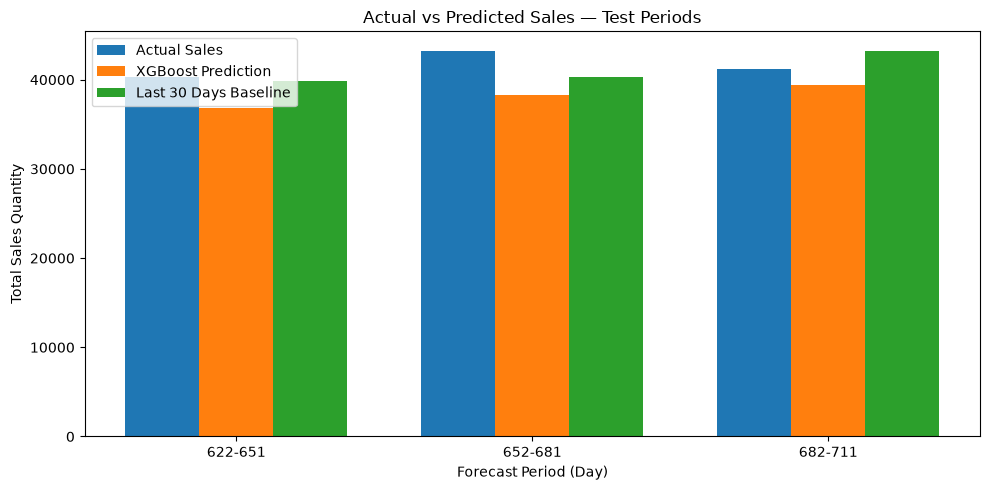

In [80]:
# 1. Aggregate predictions by forecast period
period_comparison = (
    test_results
    .groupby(["DAY", "forecast_period"], as_index=False)
    .agg(
        actual=("actual", "sum"),
        xgb_prediction=("xgb_prediction", "sum"),
        baseline_prediction=("baseline_prediction", "sum"),
    )
    .sort_values("DAY")
)

display(period_comparison.round(2))

# 2. Plot actual vs predicted totals
x = np.arange(len(period_comparison))
width = 0.25

fig, ax = plt.subplots(figsize=(10, 5))

ax.bar(
    x - width,
    period_comparison["actual"],
    width,
    label="Actual Sales",
)

ax.bar(
    x,
    period_comparison["xgb_prediction"],
    width,
    label="XGBoost Prediction",
)

ax.bar(
    x + width,
    period_comparison["baseline_prediction"],
    width,
    label="Last 30 Days Baseline",
)

ax.set_xticks(x)
ax.set_xticklabels(period_comparison["forecast_period"])
ax.set_xlabel("Forecast Period (Day)")
ax.set_ylabel("Total Sales Quantity")
ax.set_title("Actual vs Predicted Sales — Test Periods")
ax.legend()

plt.tight_layout()
plt.show()

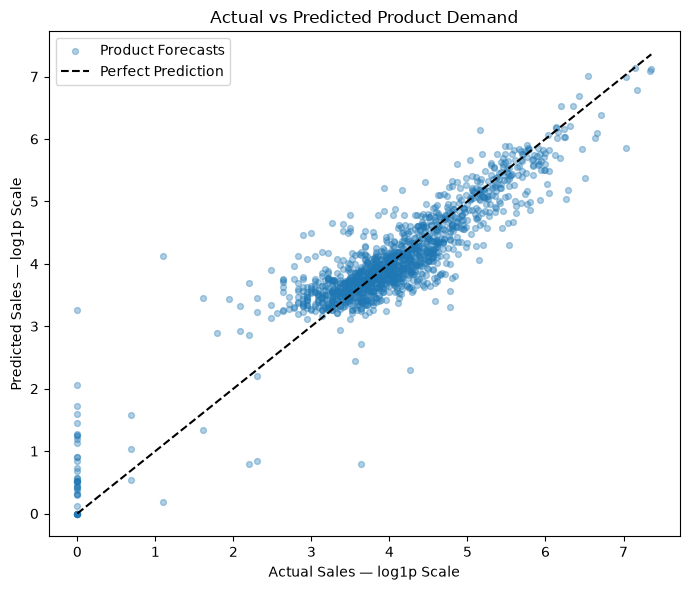

In [81]:

# Prepare values on a log scale for readability
actual_log = np.log1p(test_results["actual"])
predicted_log = np.log1p(test_results["xgb_prediction"])

# Plot predictions against actual sales
fig, ax = plt.subplots(figsize=(7, 6))

ax.scatter(
    actual_log,
    predicted_log,
    alpha=0.35,
    s=18,
    label="Product Forecasts",
)

# Perfect prediction reference line
upper_limit = max(actual_log.max(), predicted_log.max())

ax.plot(
    [0, upper_limit],
    [0, upper_limit],
    linestyle="--",
    color="black",
    label="Perfect Prediction",
)

ax.set_xlabel("Actual Sales — log1p Scale")
ax.set_ylabel("Predicted Sales — log1p Scale")
ax.set_title("Actual vs Predicted Product Demand")
ax.legend()

plt.tight_layout()
plt.show()


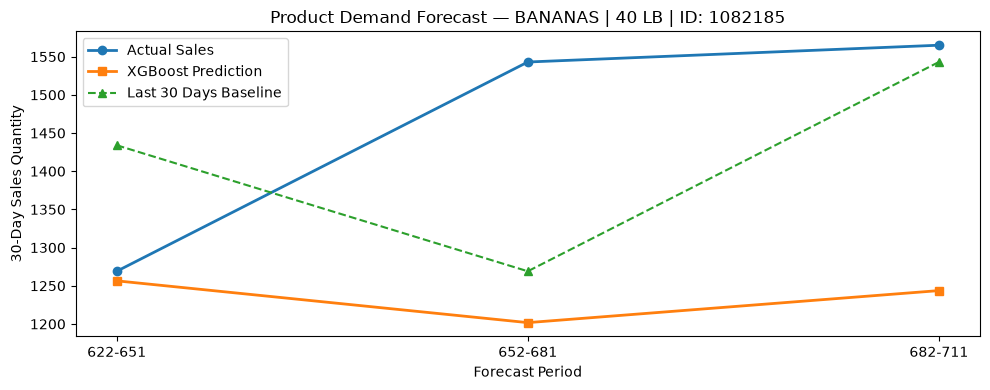

,forecast_period,actual,xgb_prediction,baseline_prediction,error,absolute_error
1038,622-651,1269.0,1256.469971,1434.0,-12.53,12.53
1039,652-681,1543.0,1201.750000,1269.0,-341.25,341.25
1040,682-711,1565.0,1243.680054,1543.0,-321.32,321.32


In [82]:

# Select a product
SELECTED_PRODUCT_ID = 1082185

product_test = test_results.loc[
    test_results["PRODUCT_ID"] == SELECTED_PRODUCT_ID
].sort_values("DAY")

assert len(product_test) == 3

product_name = product_test["product_label"].iloc[0]

# Plot product-level forecasts
fig, ax = plt.subplots(figsize=(10, 4))

ax.plot(
    product_test["forecast_period"],
    product_test["actual"],
    marker="o",
    linewidth=2,
    label="Actual Sales",
)

ax.plot(
    product_test["forecast_period"],
    product_test["xgb_prediction"],
    marker="s",
    linewidth=2,
    label="XGBoost Prediction",
)

ax.plot(
    product_test["forecast_period"],
    product_test["baseline_prediction"],
    marker="^",
    linestyle="--",
    label="Last 30 Days Baseline",
)

ax.set_title(f"Product Demand Forecast — {product_name}")
ax.set_xlabel("Forecast Period")
ax.set_ylabel("30-Day Sales Quantity")
ax.legend()

plt.tight_layout()
plt.show()

# Display product forecast errors
display(
    product_test[
        [
            "forecast_period",
            "actual",
            "xgb_prediction",
            "baseline_prediction",
            "error",
            "absolute_error",
        ]
    ].round(2)
)



## 7.12 Final Model and Artifact Saving

We selected XGBoost with a log-transformed target as our final forecasting model.

The model achieved a test MAE of 24.872 and WAPE of 27.332%.

We will save:

- The trained forecasting pipeline.
- Model metadata and feature names.
- Final test predictions.
- Product and category reference data.

The model predicts total product sales for the next 30 days across all stores.

Some high-volume products showed underprediction. This limitation will be documented.


In [83]:

import json
import joblib

# 1. Create model directory
model_dir = PROJECT_ROOT / "models"
model_dir.mkdir(parents=True, exist_ok=True)

# 2. Define artifact paths
model_path = model_dir / "demand_xgb_pipeline.joblib"

metadata_path = model_dir / "demand_model_metadata.json"

predictions_path = (
    forecast_dir / "demand_forecast_test_predictions.csv"
)

# 3. Save the trained model
joblib.dump(
    final_forecast_model,
    model_path,
)

# 4. Prepare model metadata
forecast_metadata = {
    "model_name": "XGBoost + Log Target",
    "model_type": "Global Demand Forecasting",
    "forecast_horizon_days": 30,
    "forecast_scope": "All Stores",
    "target": "target_sales_next_30d",
    "target_transformation": "log1p",
    "inverse_transformation": "expm1",
    "feature_columns": feature_cols,
    "numeric_features": numeric_cols,
    "categorical_features": categorical_cols,
    "eligible_products": int(
        eligible_products["PRODUCT_ID"].nunique()
    ),
    "train_validation_end_day": 621,
    "test_start_day": 622,
    "test_end_day": 711,
    "test_metrics": {
        key: float(value)
        for key, value in final_test_metrics.items()
    },
    "known_limitations": [
        "Forecasts may underestimate high-volume products.",
        "Predictions represent observed sales, not unconstrained demand.",
        "Store-level predictions are not supported.",
    ],
}

# 5. Save metadata
with open(
    metadata_path,
    "w",
    encoding="utf-8",
) as file:
    json.dump(
        forecast_metadata,
        file,
        indent=4,
        ensure_ascii=False,
    )

# 6. Save final test predictions
test_results.to_csv(
    predictions_path,
    index=False,
)

# 7. Verify saved model
loaded_model = joblib.load(model_path)

original_predictions = final_forecast_model.predict(
    X_forecast_test
)

loaded_predictions = loaded_model.predict(
    X_forecast_test
)

assert np.allclose(
    original_predictions,
    loaded_predictions,
    atol=1e-6,
)

print("MODEL ARTIFACTS SAVED")

print("Model:", model_path)
print("Metadata:", metadata_path)
print("Predictions:", predictions_path)

print("\nModel Reload Check: PASSED")


MODEL ARTIFACTS SAVED
Model: C:\Users\okand\Desktop\Projects\dunnhumby-retail-intelligence\models\demand_xgb_pipeline.joblib
Metadata: C:\Users\okand\Desktop\Projects\dunnhumby-retail-intelligence\models\demand_model_metadata.json
Predictions: C:\Users\okand\Desktop\Projects\dunnhumby-retail-intelligence\data\processed\forecasting\demand_forecast_test_predictions.csv

Model Reload Check: PASSED
